# Masra: tests and experimental results

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joodijana-oss/2026-GP1-18/blob/evaluation-records/evaluation/Masra_Evaluation.ipynb)

This notebook runs the app's automated tests and re-checks every number of the experimental results from the files saved in this repository.

- It sends **no request to the AI service** and costs nothing. Numbers are computed again from saved answers, saved grades and saved labels. Where that is not possible, the number is read from a saved output, and the check says so.
- It is an **independent second check in Python**. The project's own re-check is `dart run tools/rerun_evaluations.dart`; Section 1 shows its last log.
- Every comparison prints **PASS**, **FAIL** or **SKIPPED**, and Section 8 collects them. FAIL always means that a number found here does not match the saved record or the expected value. Whether a decision rule was met is written as *met* or *not met*, never as PASS or FAIL. A difference is never rounded away or hidden.
- **Section 8 gives the result at a glance.**
- It runs in about 1 to 3 minutes; the first run on a new computer takes longer, while Flutter fetches packages and compiles the tests. GitHub shows the saved outputs, so nothing has to be run to read it.

**Contents**

1. The four experiments and their records
2. Skill gaps: final held-out measurement
3. Skill gaps: first held-out round
4. Opportunity recommender
5. Matching by meaning, not adopted
6. ATS review instructions, not adopted
7. Unit tests
8. Summary: the result at a glance, and every check

**How to run it again**

- With Python 3 and Jupyter (`pip install jupyter pandas matplotlib`), Dart and Flutter installed, from the repository root:
  `python -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=1800 evaluation/Masra_Evaluation.ipynb`
- **Open in Google Colab** opens the notebook in Colab; choose *Runtime > Run all*. The first cell downloads the repository for that session.
- Colab has no Dart or Flutter, so the checks that need them (the recommender run and the unit tests) show **SKIPPED**, never PASS. All other checks still run.

## Setup

The first cells load the libraries, find the repository folder and define the helpers used by every section.

In [1]:
import os, sys, re, json, csv, math, hashlib, subprocess, shutil, platform, warnings, time
from itertools import combinations
from fractions import Fraction
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.patches
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

%matplotlib inline

T0 = time.time()

# A warning prints only its kind and its message, never a file or line.
def _show_warning(message, category, filename, lineno, file=None, line=None):
    print(f'Warning ({category.__name__}): {message}')
warnings.showwarning = _show_warning
warnings.formatwarning = lambda message, category, *args, **kwargs: f'Warning ({category.__name__}): {message}\n'

plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 100, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.axisbelow': True, 'hatch.color': '#333333', 'hatch.linewidth': 0.6})
pd.set_option('display.max_rows', 400)
pd.set_option('display.max_colwidth', 140)
pd.set_option('display.width', 200)

BLUE = '#2a78d6'    # earlier version or baseline
ORANGE = '#eb6834'  # new version or candidate
GREYS = ['#9a9a9a', '#5f5f5f', '#c4c4c4']   # extra series
EDGE = dict(edgecolor='#333333', linewidth=0.6)
# The new or candidate bars also carry a hatch, so the two series stay apart in a greyscale print.
OLD_BAR = dict(color=BLUE, **EDGE)
NEW_BAR = dict(color=ORANGE, hatch='//', **EDGE)


def find_root():
    """The repository folder: the first folder with pubspec.yaml and evaluation/README.md."""
    tried = []
    if os.environ.get('MASRA_ROOT'):
        tried.append(Path(os.environ['MASRA_ROOT']))
    here = Path.cwd().resolve()
    tried += [here, *here.parents]
    try:
        tried += sorted(p for p in here.iterdir() if p.is_dir())   # Colab: /content/<clone>
    except OSError:
        pass
    for folder in tried:
        if (folder / 'pubspec.yaml').is_file() and (folder / 'evaluation' / 'README.md').is_file():
            return folder.resolve()
    if 'google.colab' in sys.modules:
        # Colab opens only this notebook, so download the repository for this session.
        target = Path('/content/2026-GP1-18')
        if not target.exists():
            subprocess.run(['git', 'clone', '--quiet', '--depth', '1', '--branch', 'evaluation-records',
                            'https://github.com/joodijana-oss/2026-GP1-18.git', str(target)], check=True)
        print('The repository was downloaded for this Colab session.')
        return target.resolve()
    raise RuntimeError('The repository folder was not found. Open this notebook inside the cloned '
                       'repository, or set MASRA_ROOT.')


ROOT = find_root()
os.chdir(ROOT)


The repository was downloaded for this Colab session.


In [2]:
# ---------------------------------------------------------------- small helpers
def key(name):
    """The name key of the Dart tools (SkillMatcher.normalize, called keyOf there)."""
    return re.sub(r'[^a-z0-9]+', ' ', str(name).lower().replace('&', ' and ')).strip()


def rel(path):
    """A path relative to the repository folder, with forward slashes."""
    p = Path(path)
    try:
        return p.resolve().relative_to(ROOT).as_posix()
    except ValueError:
        return p.name


def read_text(path):
    return Path(path).read_text(encoding='utf-8')


_JSON_CACHE = {}
def read_json(path):
    k = str(path)
    if k not in _JSON_CACHE:
        with open(path, encoding='utf-8') as f:
            _JSON_CACHE[k] = json.load(f)
    return _JSON_CACHE[k]


def read_json_opt(path):
    return read_json(path) if Path(path).is_file() else None


def read_csv(path):
    with open(path, encoding='utf-8', newline='') as f:
        return list(csv.DictReader(f))


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def mean(values):
    values = list(values)
    return sum(values) / len(values) if values else 0.0


def frac(a, b):
    return f'{a}/{b}'


def show_table(df, index=False, digits=3):
    """A table without the 0, 1, 2, ... row numbers; numbers with `digits` decimals, whole numbers as they are."""
    with pd.option_context('display.max_colwidth', None):
        display(HTML(df.to_html(index=index, na_rep='n/a', float_format=lambda v: f'{v:.{digits}f}')))


# ---------------------------------------------------------------- tool output
# Tool output is cleaned of local folder names before anything is printed.
_SCRUB = []
def _add_scrub(path, replacement, whole=False):
    """whole=True replaces the folder together with the rest of the path that follows it."""
    if not path:
        return
    s = str(path)
    tail = r'[^\s\'"<>|]*' if whole else ''
    for v in {s, s.replace('\\', '/'), s.replace('/', '\\'), s.replace('\\', '\\\\')}:
        if len(v) > 3:
            _SCRUB.append((re.compile(re.escape(v) + tail, re.I), replacement))

_add_scrub(ROOT, '.')                                   # paths inside the repository stay readable
for _exe in ('flutter', 'dart'):
    if shutil.which(_exe):
        _add_scrub(Path(shutil.which(_exe)).resolve().parent.parent, '<sdk>')
_add_scrub(Path.home(), '<local path>', whole=True)     # anything under the home folder
_FALLBACK = [                                 # any absolute path that is still left
    (re.compile(r'file:///?\./'), ''),
    (re.compile(r'file:///?'), ''),
    (re.compile(r'(?<![A-Za-z])[A-Za-z]:[\\/][^\s\'"<>|]*'), '<local path>'),
    (re.compile(r'(?<![\w.])/(?:home|root)/[^\s\'"]*'), '<local path>'),
]


def scrub(text):
    out = text or ''
    for pattern, replacement in _SCRUB + _FALLBACK:
        out = pattern.sub(lambda m, r=replacement: r, out)
    return out


def safe_line(text, limit=300):
    """One printed line of tool output: no local folders, and app source files shown only as '[a .dart file]'."""
    line = scrub(text).strip().splitlines()[0] if (text or '').strip() else ''
    line = re.sub(r'[\w./\\:-]*\.dart\b(?::\d+)*',
                  lambda m: m.group(0) if m.group(0).replace('\\', '/').lstrip('./').startswith('test/') else '[a .dart file]', line)
    return line[:limit]


def run_tool(args, timeout=900):
    """Runs dart or flutter from the repository folder. None when the program is not installed."""
    if shutil.which(args[0]) is None:
        return None
    start = time.time()
    try:
        proc = subprocess.run(args, cwd=ROOT, capture_output=True, timeout=timeout, shell=(os.name == 'nt'))
        code, out, err = proc.returncode, proc.stdout, proc.stderr
    except subprocess.TimeoutExpired as e:
        code, out, err = -1, e.stdout or b'', (e.stderr or b'') + f'\n(stopped after {timeout} s)'.encode()
    return dict(code=code, raw=out.decode('utf-8', 'replace'), out=scrub(out.decode('utf-8', 'replace')),
                err=scrub(err.decode('utf-8', 'replace')), seconds=time.time() - start)


# ---------------------------------------------------------------- checks
CHECKS = []
GLANCE = {}      # one row per experiment for the summary of Section 8, filled by each section

# The kind of every check: what the notebook did to get the number it compares.
KINDS = {
    'recomputed': ('recomputed from raw data', 'recomputed'),    # saved answers, grades, labels or top-10 lists
    'read': ('read from saved output', 'read'),                 # a saved number, compared as it was saved
    'fingerprint': ('file fingerprint (SHA-256)', 'found'),
    'count': ('count of files or rows', 'counted'),
    'run': ('tool run now', 'found'),                           # the recommender tool or the unit tests, run here
}


def _show(v):
    if isinstance(v, bool):
        return 'yes' if v else 'no'
    if isinstance(v, Fraction):
        return f'{v.numerator}/{v.denominator} ({float(v):.4f})'
    if isinstance(v, float):
        return 'n/a' if math.isnan(v) else f'{v:.6f}'
    if isinstance(v, (set, frozenset)):
        return ', '.join(sorted(map(str, v))) if v else 'none'
    if isinstance(v, (list, tuple)):
        return ' and '.join(_show(x) for x in v) if v else 'none'
    if isinstance(v, dict):
        return ', '.join(f'{k} {_show(x)}' for k, x in v.items()) if v else 'none'
    return str(v)


def _record(section, what, found, expected, source, result, kind, verb=None):
    verb = KINDS[kind][1] if verb is None else verb
    CHECKS.append(dict(result=result, section=section, check=what, kind=KINDS[kind][0], found=str(found),
                       expected=str(expected), source=source))
    head = f'{result:<7} {what}'
    tail = f'{verb + " " if verb else ""}{found} | expected {expected}'
    if len(head) + len(tail) + 2 <= 112:
        print(f'{head}: {tail}')
    else:                                   # long lines are split, so nothing runs off the page
        print(head)
        print(' ' * 8 + tail)


def check_close(section, what, value, expected, digits, source='expected value', kind='recomputed'):
    """PASS when the two numbers agree at the precision of the expected value (half a unit of its last digit)."""
    ok = value is not None and not math.isnan(value) and abs(value - expected) <= 0.5 * 10 ** -digits + 1e-12
    if value is None or math.isnan(value):
        shown = 'n/a'
    elif kind == 'read':
        shown = f'{value:.{digits}f}'
    else:
        shown = f'{value:.{digits}f} (full {value:.6f})'
    _record(section, what, shown, f'{expected:.{digits}f}', source, 'PASS' if ok else 'FAIL', kind)


def check_exact(section, what, value, expected, source, kind='recomputed', show=_show):
    """PASS when two counts, fractions, texts or sets are equal."""
    _record(section, what, show(value), show(expected), source, 'PASS' if value == expected else 'FAIL', kind)


def check_true(section, what, ok, found, expected, source, kind='recomputed'):
    _record(section, what, found, expected, source, 'PASS' if ok else 'FAIL', kind)


def skip(section, what, reason, expected='', source='', kind='run'):
    _record(section, what, f'not run: {reason}', expected or 'n/a', source, 'SKIPPED', kind, verb='')


def section_result(section):
    rows = [c for c in CHECKS if c['section'] == section]
    n = {r: sum(1 for c in rows if c['result'] == r) for r in ('PASS', 'FAIL', 'SKIPPED')}
    text = f"**{section}: {n['PASS']} PASS, {n['FAIL']} FAIL, {n['SKIPPED']} SKIPPED.**"
    if n['FAIL']:
        text += ' Failed: ' + '; '.join(c['check'] for c in rows if c['result'] == 'FAIL')
    display(Markdown(text))


def bar_labels(ax, bars, fmt='{:.3f}'):
    """The value of each bar above it, on a white box drawn over any reference line."""
    for b in bars:
        ax.annotate(fmt.format(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points', zorder=5,
                    bbox=dict(boxstyle='square,pad=0.1', fc='white', ec='none'))

print('Helpers ready.')

Helpers ready.


**How the comparisons work**

- An expected number with *d* decimals passes when the number found here differs from it by at most half a unit of the last printed digit (0.0005 for 3 decimals, 0.005 for 2, 0.05 for 1). For a recomputed number, the full value is printed next to it. This is the only tolerance in the notebook: there is no other rounding and nothing is tuned.
- A recomputed number compared with a full-precision saved JSON value must agree within 1e-9. A value missing on one side only counts as a difference.
- Counts, fractions, texts and SHA-256 values must be equal.
- SKIPPED means the check could not run here (for example Dart or Flutter is not installed). It never counts as a pass.
- Every check has a **kind**, and its printed line says it:
  - *recomputed* from raw data (saved answers, grades, labels or top-10 lists);
  - *read* from a saved output: a number the notebook cannot recompute, compared as it was saved;
  - *found* as a file fingerprint (SHA-256), or as the result of a tool run now (the recommender tool or the unit tests);
  - *counted*: a count of files or rows.
- For a decision rule, the outcome (*met* or *not met*) is part of what is checked. PASS means that the outcome found here is the same as the saved or expected one, whichever it is.

In [28]:
def _tool_version(args, pick):
    res = run_tool(args, timeout=300)
    if res is None:
        return 'not found'
    try:
        return pick(res)
    except Exception:
        return 'found (version not read)'

env = {
    'Python': platform.python_version(),
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'matplotlib': matplotlib.__version__,
    'dart': _tool_version(['dart', '--version'],
                          lambda r: safe_line((r['out'] + r['err']).strip().splitlines()[0])),
    'flutter': _tool_version(['flutter', '--version', '--machine'],
                             lambda r: 'Flutter {frameworkVersion}, channel {channel}, Dart {dartSdkVersion}'.format(
                                 **json.loads(r['raw'][r['raw'].index('{'):r['raw'].rindex('}') + 1]))),
}
HAVE_DART = env['dart'] != 'not found'
HAVE_FLUTTER = env['flutter'] != 'not found'

git = run_tool(['git', 'rev-parse', '--short', 'HEAD'], timeout=60)
env['git commit'] = git['out'].strip() if git and git['code'] == 0 else 'not a git checkout'
status = run_tool(['git', 'status', '--porcelain', '--', 'evaluation', 'test/fixtures', 'tools', 'lib/assets/data'], timeout=60)
if status and status['code'] == 0:
    changed = [l[3:] for l in status['out'].splitlines() if l.strip() and not l[3:].startswith('evaluation/Masra_Evaluation.ipynb')]
    env['saved records changed since that commit'] = ', '.join(changed) if changed else 'none'
display(pd.DataFrame({'value': env}))

,value
Python,3.13.18
pandas,2.2.3
numpy,2.4.6
matplotlib,3.10.0
dart,not found
flutter,not found
git commit,80e5719
saved records changed since that commit,none


In [4]:
# The expected numbers. Every comparison with an expected value reads from here.
EXPECTED = {
    'gaps_final': {
        'all CVs': {'G0E0': dict(falseGap=0.185, recall=0.990, precision=0.750, f1=0.853, stability=0.581, gapsPerRun=7.0),
                    'G1E1': dict(falseGap=0.005, recall=0.956, precision=0.995, f1=0.975, stability=0.765, gapsPerRun=5.6)},
        'unseen goals': {'G0E0': dict(falseGap=0.188, recall=0.991, precision=0.746, f1=0.851),
                         'G1E1': dict(falseGap=0.000, recall=0.965, precision=1.000, f1=0.982)},
        'difference': {'FalseGap, all CVs': (-0.179, -0.240, -0.121), 'Recall, all CVs': (-0.033, -0.074, 0.000)},
    },
    'gaps_first': {'all CVs': {'G0E0': dict(falseGap=0.184, recall=0.973), 'G0E1': dict(falseGap=0.193),
                               'G1E1': dict(falseGap=0.005, recall=0.932), 'G2E1': dict(falseGap=0.000, recall=0.905)}},
    'recommender': {
        'held-out': {'nDCG@10': (0.696, 0.806), 'GapCov@10': (0.609, 0.750), 'P@5': (0.850, 0.975),
                     'TopGapRank': (13.50, 1.50), 'Ties@10': (7.25, 0.00), 'Goal-only above gap': (13.25, 0.00)},
        'development': {'nDCG@10': (0.766, 0.837), 'GapCov@10': (0.853, 0.933)},
        'held-out new nDCG@10': {'heldout_web_developer': 0.891, 'heldout_mobile_developer': 0.877,
                                 'heldout_data_scientist': 0.958, 'heldout_data_engineer': 0.878,
                                 'heldout_qa_test_engineer': 0.947, 'heldout_systems_administrator': 0.612,
                                 'heldout_business_analyst': 0.790, 'heldout_it_project_manager': 0.498},
    },
    'matching': dict(pairs=618, second_pairs=124, kappa=0.840, kappa_weighted=0.856, A0_teachhit=0.163,
                     B_teachhit=0.457, B_attrib_opp=0.691, B_attrib_cert=0.661, guard=0.70,
                     decision='DECISION: no candidate passes these rules. A0 stays.'),
    'ats': dict(recall=((62, 78), (54, 78)), change=-0.103, needed=0.100, precision=((82, 93), (75, 81)),
                invented=(3, 2), misquotes=(0, 0), hoc=(4, 1), consistency=(0.69, 0.69),
                per_cv={'old': {'ho_a': (24, 30), 'ho_b': (24, 30), 'ho_d': (14, 18)},
                        'new': {'ho_a': (29, 30), 'ho_b': (10, 30), 'ho_d': (15, 18)}},
                decision='KEEP OLD', dev=((22, 36), (33, 36)),
                rules=('not met', 'met', 'met', 'met', 'met')),
    'tests': dict(passed=575, failed=0, skipped=1, files=28),
}


## 1. The four experiments and their records

Each experiment compared a candidate with the version that was in the app before it, on data the builders did not read, under a rule written down before the measurement. `evaluation/README.md` describes every saved file. The table below lists the four experiments.

The project's own re-check, `dart run tools/rerun_evaluations.dart`, scores the saved runs again with the project's Dart tools and writes a dated log. Its last log is shown below. This notebook does the same work independently in Python, so the two checks share no scoring code.

The six skill-gap rules are coded in `tools/gap_eval/evaluate_gaps.dart` and printed at the end of each `scores.txt`; `tools/gap_eval/freeze.json` pinned the settings of the first held-out round.

In [5]:
SEC = '1. The four experiments and their records'
overview = pd.DataFrame([
    {'#': 1, 'experiment': 'Skill gaps of the AI Career Analysis', 'folder': 'evaluation/skill_gaps/',
     'compared': 'G0E0 (original) vs G1E1 (candidate)',
     'rule fixed in advance': 'six rules in tools/gap_eval/evaluate_gaps.dart, printed at the end of scores.txt',
     'held-out data': 'test/fixtures/cv_eval_final: 16 CVs, 3 runs each', 'decision': 'G1E1 adopted'},
    {'#': 2, 'experiment': 'Opportunity Recommender ranking', 'folder': 'evaluation/recommender/',
     'compared': 'baseline vs new recommender',
     'rule fixed in advance': 'none; differences of about 0.02 are noise',
     'held-out data': 'test/fixtures/opportunity_eval_personas_heldout.json: 8 test users', 'decision': 'new recommender adopted'},
    {'#': 3, 'experiment': 'Matching skill gaps to items by meaning', 'folder': 'evaluation/matching/',
     'compared': 'A0 (word matching) vs B and B-opp (typed links); word control L1g',
     'rule fixed in advance': 'tools/gap_eval/decision_rule_r2.txt, pinned by tools/gap_eval/freeze_r2.json',
     'held-out data': '61 decision names, 618 graded pairs', 'decision': 'not adopted: A0 stays'},
    {'#': 4, 'experiment': 'ATS review instructions', 'folder': 'evaluation/ats_review/',
     'compared': 'OLD vs NEW review text', 'rule fixed in advance': 'tools/ats_eval/decision_rule.txt',
     'held-out data': 'evaluation/ats_review/heldout_set: 4 CVs, 3 runs per version', 'decision': 'not adopted: KEEP OLD'},
]).set_index('#')
display(overview)

log_path = Path('evaluation/logs/rerun_2026-11-22.txt')
log_lines = read_text(log_path).splitlines()
log_rows = [{'result': m.group(1), 'check': m.group(2)}
            for m in (re.match(r'^(SAME|DIFFERENT|SKIPPED)\s+(.*)', l) for l in log_lines) if m]
print(f'Lines of {rel(log_path)} (the project\'s own Dart re-check):')
show_table(pd.DataFrame(log_rows))
summary_line = [l for l in log_lines if l.startswith('SUMMARY:')][-1]
check_exact(SEC, 'summary line of the project re-check log', summary_line,
            'SUMMARY: 9 same, 0 different, 1 skipped.', rel(log_path), kind='read')

counts = [
    ('evaluation/skill_gaps/final_run/raw/gaps', 96, '16 CVs x 2 versions x 3 runs'),
    ('evaluation/skill_gaps/final_run/raw/market', 54, '9 career goals x 2 extractors x 3 runs'),
    ('evaluation/skill_gaps/first_run/raw/gaps', 192, '16 CVs x 4 versions x 3 runs'),
]
rows = []
for folder, expected, why in counts:
    n = sum(1 for p in Path(folder).iterdir() if p.is_file() and p.suffix == '.json')
    rows.append({'folder': folder, 'files': n, 'expected': expected, 'because': why})
    check_exact(SEC, f'saved answer files in {folder}', n, expected, why, kind='count')
show_table(pd.DataFrame(rows))
section_result(SEC)

,experiment,folder,compared,rule fixed in advance,held-out data,decision
#,,,,,,
1,Skill gaps of the AI Career Analysis,evaluation/skill_gaps/,G0E0 (original) vs G1E1 (candidate),"six rules in tools/gap_eval/evaluate_gaps.dart, printed at the end of scores.txt","test/fixtures/cv_eval_final: 16 CVs, 3 runs each",G1E1 adopted
2,Opportunity Recommender ranking,evaluation/recommender/,baseline vs new recommender,none; differences of about 0.02 are noise,test/fixtures/opportunity_eval_personas_heldout.json: 8 test users,new recommender adopted
3,Matching skill gaps to items by meaning,evaluation/matching/,A0 (word matching) vs B and B-opp (typed links); word control L1g,"tools/gap_eval/decision_rule_r2.txt, pinned by tools/gap_eval/freeze_r2.json","61 decision names, 618 graded pairs",not adopted: A0 stays
4,ATS review instructions,evaluation/ats_review/,OLD vs NEW review text,tools/ats_eval/decision_rule.txt,"evaluation/ats_review/heldout_set: 4 CVs, 3 runs per version",not adopted: KEEP OLD


Lines of evaluation/logs/rerun_2026-11-22.txt (the project's own Dart re-check):


result,check
SAME,"skill gaps, final_run: scores.txt"
SAME,"skill gaps, first_run: scores.txt"
SAME,"recommender, development test users (without TIMING)"
SAME,"recommender, held-out test users (without TIMING)"
SAME,ATS held-out scorer
SAME,ATS development scorer
SAME,SHA-256 of evaluation/matching/final_run/judgements/teaching.csv
SAME,SHA-256 of evaluation/matching/final_run/judgements/teaching_second.csv
SAME,SHA-256 of evaluation/matching/final_run/review/matching_scores_r2.txt
SKIPPED,"matching scores: not scored again: the scoring tool checks the freeze in tools/gap_eval/freeze_r2.json and refuses to run on later code (see evaluation/README.md, ""Matching by meaning"")."


PASS    summary line of the project re-check log
        read SUMMARY: 9 same, 0 different, 1 skipped. | expected SUMMARY: 9 same, 0 different, 1 skipped.
PASS    saved answer files in evaluation/skill_gaps/final_run/raw/gaps: counted 96 | expected 96
PASS    saved answer files in evaluation/skill_gaps/final_run/raw/market: counted 54 | expected 54
PASS    saved answer files in evaluation/skill_gaps/first_run/raw/gaps: counted 192 | expected 192


folder,files,expected,because
evaluation/skill_gaps/final_run/raw/gaps,96,96,16 CVs x 2 versions x 3 runs
evaluation/skill_gaps/final_run/raw/market,54,54,9 career goals x 2 extractors x 3 runs
evaluation/skill_gaps/first_run/raw/gaps,192,192,16 CVs x 4 versions x 3 runs


**1. The four experiments and their records: 4 PASS, 0 FAIL, 0 SKIPPED.**

## 2. Skill gaps: final held-out measurement

**What was tested.** The step of the AI Career Analysis that lists the skills a user still lacks for a career goal (the skill gaps). G0E0 is the original step (two lists of skill names). G1E1 is the candidate: single-skill market names, each checked against a quote from the CV. G1E1 is what the app runs now.

**Data.** 16 fictional CVs in `test/fixtures/cv_eval_final/` with answer keys written by the team (skills each CV *shows*, shows *partly*, or does *not show*), 3 runs per CV and version. The saved answers of the AI service are in `evaluation/skill_gaps/final_run/raw/`. 12 of the CVs have career goals whose CVs the developers did not see during development ("unseen goals"); the 4 CVs of the two goals they saw (cybersecurity analyst and data analyst) are reported apart.

**Metrics** (defined in `tools/gap_eval/gap_scoring.dart`; each CV weighs the same and its runs are averaged first):
- *FalseGap* = gaps the CV clearly shows / all judged gaps (lower is better; the main number).
- *Recall* = market skills the CV does not show that were returned as gaps / all market skills the CV does not show.
- *Precision* = not-shown gaps / judged gaps that are not "partly".
- *F1* from the macro precision and recall; *Stability* = mean pairwise Jaccard of the gap lists of the 3 runs; *gaps/run* = mean number of gaps in one run.

**Rule fixed in advance.** Six rules, coded in `tools/gap_eval/evaluate_gaps.dart` and printed at the end of `scores.txt`: every run gave a result; recall at most 0.05 below G0E0; at most 2% bundled gap names; fallback in at most 10% of runs; FalseGap at least 0.05 lower on all CVs with a 95% bootstrap interval below 0; and at least 0.05 lower on unseen goals.

**Where the reviewers' judgements are.** Gap names that are not in an answer key were judged by reviewers in `<test set>/judgements/names.csv` (here `test/fixtures/cv_eval_final/judgements/names.csv`); that is the file the scores read. The README calls `review/names_review.csv` and `review/names_second.csv` "the review of gap names that are not in the answer keys", but neither holds judgements: `names_review.csv` is the queue of names still waiting for review and holds only its header (so the scores are final, not provisional), and `names_second.csv` is a second-rater sheet that was never filled in, so no rater agreement exists for skill gaps.

**Result.** G1E1 lowers FalseGap from 0.185 to 0.005 while recall stays within the limit (0.990 to 0.956); it meets all six rules and was adopted.

The next cell is the Python port of `tools/gap_eval/eval_data.dart` and `gap_scoring.dart`. It is long; the results follow it.

In [6]:
# ------------------------------------------------------------------ skill-gap scoring (a Python port of
# tools/gap_eval/eval_data.dart and gap_scoring.dart; nothing is imported from the project)
SEEN_GOALS = {'cybersecurity_analyst', 'data_analyst'}          # tools/gap_eval/eval_support.dart
SPLITS = {'all CVs': None,
          'unseen goals': lambda c: c['goal'] not in SEEN_GOALS,
          'seen goals': lambda c: c['goal'] in SEEN_GOALS}
STATUS_PARTS = [('shown', 'shown'), ('partly', 'partly'), ('notShown', 'not_shown')]
GAP_METRICS = ['cvs', 'falseGap', 'cvsWithFalseGap', 'recall', 'precision', 'f1', 'bundled', 'stability',
               'fallbackRate', 'unverifiedQuoteRate', 'gapsPerRun', 'errors', 'emptyGapRuns', 'recallSkipped', 'unjudged']
RULE_TEXTS = ['every run gave a result', 'recall not more than 0.05 below G0E0',
              'bundled gap names at most 2% (reviewers)', 'fallback in at most 10% of the runs',
              'FalseGap at least 0.05 lower on all CVs, interval excludes 0',
              'FalseGap at least 0.05 lower on unseen goals (point estimate)']
# The main metrics; the other fields are internal counts.
METRIC_LABELS = {'cvs': 'CVs scored', 'falseGap': 'FalseGap',
                 'cvsWithFalseGap': 'runs with at least one false gap (share, mean over CVs)',
                 'recall': 'Recall', 'precision': 'Precision', 'f1': 'F1', 'bundled': 'bundled gap names (reviewers)',
                 'stability': 'Stability', 'fallbackRate': 'fallback rate', 'unverifiedQuoteRate': 'unverified quote rate',
                 'gapsPerRun': 'gaps/run', 'errors': 'runs with an error', 'emptyGapRuns': 'runs with no gap',
                 'recallSkipped': 'runs with no not-shown market skill', 'unjudged': 'names without a judgement'}
MAIN_METRICS = ['falseGap', 'recall', 'precision', 'f1', 'stability', 'gapsPerRun']


def load_gap_set(set_path):
    set_path = Path(set_path)
    manifest = read_json(set_path / 'manifest.json')
    roles = read_json(set_path / 'roles.json') if (set_path / 'roles.json').is_file() else {}
    cases = []
    for item in manifest['cases']:
        labels = read_json(set_path / item['labels'])
        status = {}
        # first the skills' own names, then their other names, so another skill's
        # "also called" name never overrides a skill's own name
        for part, value in STATUS_PARTS:
            for e in labels.get(part) or []:
                k = key(e.get('skill') or '')
                if k:
                    status.setdefault(k, value)
        for part, value in STATUS_PARTS:
            for e in labels.get(part) or []:
                for name in [e.get('skill') or ''] + list(e.get('alsoCalled') or []):
                    k = key(name)
                    if k:
                        status.setdefault(k, value)
        # the other names of the role skills point to the same label
        for role in roles.get(item['careerGoalId']) or []:
            names = [k for k in (key(n) for n in [role.get('skill') or ''] + list(role.get('alsoCalled') or [])) if k]
            known = [k for k in names if k in status]
            if known:
                for k in names:
                    status.setdefault(k, status[known[0]])
        cases.append(dict(id=str(item['id']), goal=str(item['careerGoalId']), status=status))
    judgements, rows = {}, []
    names_csv = set_path / 'judgements' / 'names.csv'
    if names_csv.is_file():
        rows = read_csv(names_csv)
    for row in rows:
        s = (row.get('status') or '').lower().replace(' ', '_')
        if s not in ('shown', 'partly', 'not_shown'):
            continue
        b = (row.get('bundled') or '').lower()
        judgements[(row.get('case_id') or '', key(row.get('name') or ''))] = (s, True if b == 'yes' else (False if b == 'no' else None))
    return dict(path=set_path, manifest=manifest, cases=cases, judgements=judgements, names_rows=len(rows))


def status_of(gs, case, name):
    k = key(name)
    if k in case['status']:
        return case['status'][k]
    j = gs['judgements'].get((case['id'], k))
    return j[0] if j else None


def bundled_of(gs, case, name):
    k = key(name)
    if k in case['status']:
        return False                      # a label skill is one skill by the rules of the labels
    j = gs['judgements'].get((case['id'], k))
    return j[1] if j else None


def jaccard_mean(sets):
    vals = []
    for i in range(len(sets)):
        for j in range(i + 1, len(sets)):
            union = len(sets[i] | sets[j])
            vals.append(1.0 if union == 0 else len(sets[i] & sets[j]) / union)
    return mean(vals) if vals else 1.0


def score_arm(run_dir, gs, arm, runs, only=None):
    ext = 'E' + arm[-1]
    fg_case, rc_case = {}, {}
    with_fg, prec_case, bund_case, stab_case, gap_counts = [], [], [], [], []
    fallbacks = records = unverified = checked = errors = empty_runs = recall_skipped = 0
    unjudged = set()
    for c in gs['cases']:
        if only is not None and not only(c):
            continue
        fgs, rcs, ps, bs, sets = [], [], [], [], []
        any_false = scored = 0
        for r in range(1, runs + 1):
            g = read_json_opt(run_dir / 'raw' / 'gaps' / f"{c['id']}_{arm}_r{r}.json")
            m = read_json_opt(run_dir / 'raw' / 'market' / f"{c['goal']}_{ext}_r{r}.json")
            targets = None if (m is None or m.get('error') is not None) else [str(x) for x in (m.get('names') or [])]
            if g is None or g.get('error') is not None or targets is None:
                errors += 1                    # a run with a non-null error value, or a missing file
                continue
            records += 1
            scored += 1
            gaps = [str(x) for x in (g.get('gaps') or [])]
            if g.get('usedFallback') is True:
                fallbacks += 1
            unverified += int(g.get('unverifiedQuotes') or 0)
            checked += len(g['statuses']) if isinstance(g.get('statuses'), list) else 0
            gap_counts.append(len(gaps))
            if not gaps:
                empty_runs += 1
            sets.append({key(x) for x in gaps})
            shown = not_shown = partly = judged = bundled = bundled_judged = 0
            for x in gaps:
                s = status_of(gs, c, x)
                if s == 'shown':
                    shown += 1; judged += 1
                elif s == 'partly':
                    partly += 1; judged += 1
                elif s == 'not_shown':
                    not_shown += 1; judged += 1
                else:
                    unjudged.add((c['id'], key(x)))
                b = bundled_of(gs, c, x)
                if b is not None:
                    bundled_judged += 1
                    bundled += int(b)
            fgs.append(0.0 if judged == 0 else shown / judged)
            if shown > 0:
                any_false += 1
            if judged - partly > 0:
                ps.append(not_shown / (judged - partly))
            if bundled_judged > 0:
                bs.append(bundled / bundled_judged)
            gap_keys = {key(x) for x in gaps}
            missing = found = 0
            for t in targets:
                s = status_of(gs, c, t)
                if s is None:
                    unjudged.add((c['id'], key(t)))
                if s != 'not_shown':
                    continue
                missing += 1
                if key(t) in gap_keys:
                    found += 1
            if missing == 0:
                recall_skipped += 1
            else:
                rcs.append(found / missing)
        if scored == 0:
            continue
        fg_case[c['id']] = mean(fgs)
        rc_case[c['id']] = mean(rcs) if rcs else math.nan
        with_fg.append(any_false / scored)
        if ps:
            prec_case.append(mean(ps))
        if bs:
            bund_case.append(mean(bs))
        stab_case.append(jaccard_mean(sets))
    R = mean(v for v in rc_case.values() if not math.isnan(v))
    P = mean(prec_case)
    return dict(cvs=len(fg_case), falseGap=mean(fg_case.values()), cvsWithFalseGap=mean(with_fg), recall=R,
                precision=P, f1=0.0 if P + R <= 0 else 2 * P * R / (P + R), bundled=mean(bund_case),
                stability=mean(stab_case), fallbackRate=0.0 if records == 0 else fallbacks / records,
                unverifiedQuoteRate=0.0 if checked == 0 else unverified / checked, gapsPerRun=mean(gap_counts),
                errors=errors, emptyGapRuns=empty_runs, recallSkipped=recall_skipped, unjudged=len(unjudged),
                by_case_fg=fg_case, by_case_rc=rc_case)


def market_bundled(run_dir, gs, extractor, runs):
    """Share of the market skill names that reviewers marked as bundled (several skills in one name)."""
    names = judged = bundled = 0
    for c in gs['cases']:
        for r in range(1, runs + 1):
            m = read_json_opt(run_dir / 'raw' / 'market' / f"{c['goal']}_{extractor}_r{r}.json")
            for name in ([] if m is None or m.get('error') is not None else [str(x) for x in m.get('names') or []]):
                names += 1
                b = bundled_of(gs, c, name)
                if b is not None:
                    judged += 1
                    bundled += int(b)
    return (bundled / judged if judged else math.nan), names


# ------------------------------------------------------------------ the paired bootstrap of the Dart tool
# Dart's Random(seed) is ported exactly, so the intervals can be compared with the saved ones.
M64 = (1 << 64) - 1

def _mix64(n):
    n &= M64
    n = (~n + (n << 21)) & M64
    n ^= n >> 24
    n = (n * 265) & M64
    n ^= n >> 14
    n = (n * 21) & M64
    n ^= n >> 28
    n = (n + (n << 31)) & M64
    return n


class DartRandom:
    def __init__(self, seed):
        s = _mix64(seed) or 0x5a17
        self.lo, self.hi = s & 0xffffffff, s >> 32
        for _ in range(4):
            self._next()

    def _next(self):
        st = 0xffffda61 * self.lo + self.hi
        self.lo, self.hi = st & 0xffffffff, (st >> 32) & 0xffffffff

    def next_int(self, m):
        if m & -m == m:
            self._next()
            return self.lo & (m - 1)
        while True:
            self._next()
            r = self.lo
            res = r % m
            if r - res + m <= (1 << 32):
                return res


# The Dart scorer (pairedDifference in gap_scoring.dart) calls bootstrapInterval with its default seed 20261119,
# not with the seed of config.json, so the port does the same. partlyIsGap in config.json changes which gaps the
# app returns during a run, not how the saved answers are scored, so the scorer does not read it.
def bootstrap_interval(diffs, rounds=10000, seed=20261119):
    rnd, n, vals = DartRandom(seed), len(diffs), []
    for _ in range(rounds):
        s = 0.0
        for _ in range(n):
            s += diffs[rnd.next_int(n)]
        vals.append(s / n)
    vals.sort()
    at = lambda p: vals[min(max(math.floor(p * (len(vals) - 1) + 0.5), 0), len(vals) - 1)]
    return at(0.025), at(0.975)


def paired(candidate, baseline):
    ids = [i for i in candidate if i in baseline and not math.isnan(candidate[i]) and not math.isnan(baseline[i])]
    if not ids:
        return dict(diff=math.nan, low=math.nan, high=math.nan, cvs=0)
    d = [candidate[i] - baseline[i] for i in ids]
    low, high = bootstrap_interval(d)
    return dict(diff=mean(d), low=low, high=high, cvs=len(ids))


def score_gap_run(run_dir):
    run_dir = Path(run_dir)
    cfg = read_json(run_dir / 'config.json')
    gs = load_gap_set(cfg['setPath'])
    arms, runs = list(cfg['arms']), int(cfg['runs'])
    scores = {split: {arm: score_arm(run_dir, gs, arm, runs, only) for arm in arms} for split, only in SPLITS.items()}
    base, unseen_base = scores['all CVs']['G0E0'], scores['unseen goals']['G0E0']
    against = {}
    for arm in arms:
        if arm == 'G0E0':
            continue
        a, u = scores['all CVs'][arm], scores['unseen goals'][arm]
        d_all = paired(a['by_case_fg'], base['by_case_fg'])
        d_unseen = paired(u['by_case_fg'], unseen_base['by_case_fg'])
        d_recall = paired(a['by_case_rc'], base['by_case_rc'])
        verdicts = [a['errors'] == 0, a['recall'] >= base['recall'] - 0.05, a['bundled'] <= 0.02,
                    a['fallbackRate'] <= 0.10, d_all['diff'] <= -0.05 and d_all['high'] < 0,
                    d_unseen['cvs'] > 0 and d_unseen['diff'] <= -0.05]
        against[arm] = dict(intervals={'FalseGap, all CVs': d_all, 'FalseGap, unseen goals': d_unseen,
                                       'Recall, all CVs': d_recall},
                            rules=list(zip(verdicts, RULE_TEXTS)))
    passed = sorted([arm for arm, v in against.items() if all(ok for ok, _ in v['rules'])],
                    key=lambda arm: scores['all CVs'][arm]['falseGap'])
    decision = ('DECISION: arms that pass every rule, lowest FalseGap first: ' + ', '.join(passed)) if passed \
        else "DECISION: no arm passes every rule. Today's analysis stays."
    market = {ext: market_bundled(run_dir, gs, ext, runs) for ext in sorted({'E' + a[-1] for a in arms})}
    return dict(run_dir=run_dir, cfg=cfg, gs=gs, arms=arms, runs=runs, scores=scores, against=against,
                decision=decision, market=market)


INTERVAL_RE = re.compile(r'(FalseGap, all CVs|FalseGap, unseen goals|Recall, all CVs)\s*:\s*'
                         r'([+-]\d\.\d{3})\s+\[([+-]\d\.\d{3}), ([+-]\d\.\d{3})\]')

def parse_gap_scores_txt(path):
    text = read_text(path)
    block = text[text.index('AGAINST G0E0'):]
    if 'GAPS PER CV' in block:
        block = block[:block.index('GAPS PER CV')]          # the per-CV gap names are never printed here
    intervals, rules, arm = {}, {}, None
    for ln in block.splitlines():
        m = re.match(r'^  (G\dE\d)$', ln)
        if m:
            arm = m.group(1)
            intervals[arm], rules[arm] = {}, []
            continue
        m = INTERVAL_RE.search(ln)
        if m and arm:
            intervals[arm][m.group(1)] = tuple(float(m.group(k)) for k in (2, 3, 4))
            continue
        m = re.match(r'^\s+(pass|FAIL)\s+(.*)', ln)
        if m and arm:
            rules[arm].append((m.group(1) == 'pass', m.group(2).strip()))
    decision = next(l for l in block.splitlines() if l.startswith('DECISION:'))
    market = {m.group(1): (float(m.group(2)), int(m.group(3)))
              for m in re.finditer(r'^\s+(E\d): reviewers ([0-9.]+), detector [0-9.]+\s+\((\d+) names\)', text, re.M)}
    return dict(intervals=intervals, rules=rules, decision=decision, market=market,
                not_heldout_note='This is not the held-out set' in block)


def compare_gap_run(sec, result, splits_to_check):
    """Every recomputed metric against scores.json: one check per split and version.
    Returns the main metrics (3 decimals) and a short table of the largest difference over all 15 metrics."""
    saved_path = result['run_dir'] / 'scores.json'
    saved = read_json(saved_path)
    rows, largest = [], []
    for split in SPLITS:
        for arm in result['arms']:
            mine, theirs = result['scores'][split][arm], saved[split][arm]
            worst = 0.0
            for metric in GAP_METRICS:
                a, b = float(mine[metric]), float(theirs[metric])
                if math.isnan(a) and math.isnan(b):
                    d = 0.0
                elif math.isnan(a) or math.isnan(b):
                    d = math.inf                    # a value on one side only is a difference, never dropped
                else:
                    d = abs(a - b)
                worst = max(worst, d)
                rows.append(dict(split=split, version=arm, metric=metric, recomputed=a, saved=b, difference=d))
            check_true(sec, f'{split}, {arm}: all {len(GAP_METRICS)} metrics equal scores.json',
                       worst <= 1e-9, f'largest difference {worst:.1e}', 'at most 1e-9', rel(saved_path))
            largest.append({'split': split, 'version': arm, 'metrics compared': len(GAP_METRICS),
                            'largest difference': f'{worst:.1e}'})
    shown = []
    for split in splits_to_check:
        for metric in MAIN_METRICS:
            row = {'split': split, 'metric': METRIC_LABELS[metric]}
            for arm in result['arms']:
                row[f'{arm} recomputed'] = f"{result['scores'][split][arm][metric]:.3f}"
                row[f'{arm} saved'] = f"{float(saved[split][arm][metric]):.3f}"
            shown.append(row)
    return pd.DataFrame(rows), pd.DataFrame(shown).set_index(['split', 'metric']), pd.DataFrame(largest)


def outcome(ok):
    return 'met' if ok else 'not met'


def compare_against(sec, result, parsed, txt_path):
    rows = []
    for arm, v in result['against'].items():
        for label, d in v['intervals'].items():
            saved = parsed['intervals'].get(arm, {}).get(label)
            mine = (d['diff'], d['low'], d['high'])
            ok = saved is not None and all(abs(x - y) <= 0.0005 + 1e-12 for x, y in zip(mine, saved))
            mine_txt = f'{d["diff"]:+.3f} [{d["low"]:+.3f}, {d["high"]:+.3f}] ({d["cvs"]} CVs)'
            saved_txt = 'missing' if saved is None else f'{saved[0]:+.3f} [{saved[1]:+.3f}, {saved[2]:+.3f}]'
            rows.append({'version': arm, 'difference against G0E0': label, 'recomputed': mine_txt, 'saved': saved_txt})
            check_true(sec, f'{arm} - G0E0, {label}: difference and 95% interval', ok, mine_txt, saved_txt, rel(txt_path))
        mine_rules = [(ok, text) for ok, text in v['rules']]
        saved_rules = parsed['rules'].get(arm, [])
        check_true(sec, f'{arm}: outcome of the six decision rules, in order', mine_rules == saved_rules,
                   ', '.join(outcome(ok) for ok, _ in mine_rules),
                   ', '.join(outcome(ok) for ok, _ in saved_rules), rel(txt_path))
    check_exact(sec, 'decision line', result['decision'], parsed['decision'], rel(txt_path))
    for ext, (share, n) in result['market'].items():
        saved_share, saved_n = parsed['market'][ext]
        check_true(sec, f'market names {ext}: share marked bundled by reviewers, and number of names',
                   abs(share - saved_share) <= 0.0005 + 1e-12 and n == saved_n,
                   f'{share:.3f} of {n}', f'{saved_share:.3f} of {saved_n}', rel(txt_path))
    rules_table = pd.DataFrame([
        {'version': arm, 'rule': text, 'rule outcome (recomputed)': outcome(ok),
         'rule outcome (saved)': next((outcome(s_ok) for s_ok, s_text in parsed['rules'].get(arm, []) if s_text == text), 'missing')}
        for arm, v in result['against'].items() for ok, text in v['rules']])
    return pd.DataFrame(rows), rules_table

print('Skill-gap scoring code ready.')

Skill-gap scoring code ready.


In [7]:
SEC = '2. Skill gaps: final held-out measurement'
t = time.time()
FINAL = score_gap_run('evaluation/skill_gaps/final_run')
final_txt = FINAL['run_dir'] / 'scores.txt'
FINAL_TXT = parse_gap_scores_txt(final_txt)
print(f"Test set {rel(FINAL['gs']['path'])}: {len(FINAL['gs']['cases'])} CVs, versions {', '.join(FINAL['arms'])}, "
      f"{FINAL['runs']} runs; reviewer judgements: {FINAL['gs']['names_rows']} rows in "
      f"{rel(FINAL['gs']['path'] / 'judgements' / 'names.csv')}. Scored in {time.time() - t:.1f} s.")

review_rows = read_csv(FINAL['run_dir'] / 'review' / 'names_review.csv')
second_rows = read_csv(FINAL['run_dir'] / 'review' / 'names_second.csv')
check_exact(SEC, 'names waiting for review (rows of review/names_review.csv)', len(review_rows), 0,
            rel(FINAL['run_dir'] / 'review' / 'names_review.csv'), kind='count')
print(f"review/names_second.csv: {len(second_rows)} rows, "
      f"{sum(1 for r in second_rows if (r.get('status') or '').strip())} with a status filled in (no second rating exists).")

table_final, shown_final, largest_final = compare_gap_run(SEC, FINAL, splits_to_check=list(SPLITS))
print("\nThe main metrics, recomputed, next to the saved scores.json value (3 decimals):")
display(shown_final)
print(f'All {len(GAP_METRICS)} metrics of scores.json were compared, including internal counts that are not shown above '
      f'print ({", ".join(METRIC_LABELS[m] for m in GAP_METRICS if m not in MAIN_METRICS)}):')
show_table(largest_final)
detector = read_json(FINAL['run_dir'] / 'scores.json')['all CVs']
print("Not recomputed: 'Bundled (detector)', the share of gap names that the app's name-shape detector flags, "
      "because it needs the app's Dart code and catalogue names. Saved values: "
      + ', '.join(f"{arm} {detector[arm]['bundledByDetector']:.3f}" for arm in FINAL['arms']) + '.')

Test set test/fixtures/cv_eval_final: 16 CVs, versions G0E0, G1E1, 3 runs; reviewer judgements: 194 rows in test/fixtures/cv_eval_final/judgements/names.csv. Scored in 0.8 s.
PASS    names waiting for review (rows of review/names_review.csv): counted 0 | expected 0
review/names_second.csv: 39 rows, 0 with a status filled in (no second rating exists).
PASS    all CVs, G0E0: all 15 metrics equal scores.json
        recomputed largest difference 2.2e-16 | expected at most 1e-9
PASS    all CVs, G1E1: all 15 metrics equal scores.json
        recomputed largest difference 0.0e+00 | expected at most 1e-9
PASS    unseen goals, G0E0: all 15 metrics equal scores.json
        recomputed largest difference 1.1e-16 | expected at most 1e-9
PASS    unseen goals, G1E1: all 15 metrics equal scores.json
        recomputed largest difference 0.0e+00 | expected at most 1e-9
PASS    seen goals, G0E0: all 15 metrics equal scores.json
        recomputed largest difference 2.2e-16 | expected at most 1e-9
PASS

G0E0 recomputed G0E0 saved G1E1 recomputed G1E1 saved
split        metric                                                         
all CVs      FalseGap            0.185      0.185           0.005      0.005
             Recall              0.990      0.990           0.956      0.956
             Precision           0.750      0.750           0.995      0.995
             F1                  0.853      0.853           0.975      0.975
             Stability           0.581      0.581           0.765      0.765
             gaps/run            7.021      7.021           5.604      5.604
unseen goals FalseGap            0.188      0.188           0.000      0.000
             Recall              0.991      0.991           0.965      0.965
             Precision           0.746      0.746           1.000      1.000
             F1                  0.851      0.851           0.982      0.982
             Stability           0.603      0.603           0.788      0.788
             gaps/run            6.611      6.611           5.361      5.361
seen goals   FalseGap            0.173      0.173           0.021      0.021
             Recall              0.986      0.986           0.932      0.932
             Precision           0.763      0.763           0.979      0.979
             F1                  0.861      0.861           0.955      0.955
             Stability           0.516      0.516           0.698      0.698
             gaps/run            8.250      8.250           6.333      6.333

All 15 metrics of scores.json were compared, including internal counts that are not shown above print (CVs scored, runs with at least one false gap (share, mean over CVs), bundled gap names (reviewers), fallback rate, unverified quote rate, runs with an error, runs with no gap, runs with no not-shown market skill, names without a judgement):


split,version,metrics compared,largest difference
all CVs,G0E0,15,2.2e-16
all CVs,G1E1,15,0.0e+00
unseen goals,G0E0,15,1.1e-16
unseen goals,G1E1,15,0.0e+00
seen goals,G0E0,15,2.2e-16
seen goals,G1E1,15,0.0e+00


Not recomputed: 'Bundled (detector)', the share of gap names that the app's name-shape detector flags, because it needs the app's Dart code and catalogue names. Saved values: G0E0 0.164, G1E1 0.000.


In [8]:
print('Comparison with the expected values:')
for split, arms in EXPECTED['gaps_final'].items():
    if split == 'difference':
        continue
    for arm, metrics in arms.items():
        for metric, expected in metrics.items():
            check_close(SEC, f'{split}, {arm}: {METRIC_LABELS[metric]}', FINAL['scores'][split][arm][metric], expected,
                        1 if metric == 'gapsPerRun' else 3)

for label, (d, lo, hi) in EXPECTED['gaps_final']['difference'].items():
    got = FINAL['against']['G1E1']['intervals'][label]
    check_close(SEC, f'G1E1 - G0E0, {label}: difference', got['diff'], d, 3)
    check_true(SEC, f'G1E1 - G0E0, {label}: 95% bootstrap interval',
               abs(got['low'] - lo) <= 0.0005 + 1e-12 and abs(got['high'] - hi) <= 0.0005 + 1e-12,
               f"[{got['low']:+.3f}, {got['high']:+.3f}]", f'[{lo:+.3f}, {hi:+.3f}]', 'expected value')

print('\nDifferences, the six rules and the decision, against the saved scores.txt:')
intervals_final, rules_final = compare_against(SEC, FINAL, FINAL_TXT, final_txt)
display(intervals_final.set_index(['version', 'difference against G0E0']))
display(rules_final.set_index(['version', 'rule']))

_g0, _g1 = FINAL['scores']['all CVs']['G0E0'], FINAL['scores']['all CVs']['G1E1']
_rules = FINAL['against']['G1E1']['rules']
GLANCE['gaps'] = {
    'experiment': 'Skill gaps (final held-out set)',
    'compared': 'G0E0 (original) vs G1E1 (candidate)',
    'main number, earlier -> new': f"FalseGap {_g0['falseGap']:.3f} -> {_g1['falseGap']:.3f}; "
                                   f"Recall {_g0['recall']:.3f} -> {_g1['recall']:.3f}",
    'rule outcome': f"G1E1 meets {sum(ok for ok, _ in _rules)} of {len(_rules)} rules",
    'decision': 'G1E1 adopted' if FINAL['decision'].endswith('G1E1') else FINAL['decision'],
}

Comparison with the expected values:
PASS    all CVs, G0E0: FalseGap: recomputed 0.185 (full 0.184510) | expected 0.185
PASS    all CVs, G0E0: Recall: recomputed 0.990 (full 0.989583) | expected 0.990
PASS    all CVs, G0E0: Precision: recomputed 0.750 (full 0.750289) | expected 0.750
PASS    all CVs, G0E0: F1: recomputed 0.853 (full 0.853481) | expected 0.853
PASS    all CVs, G0E0: Stability: recomputed 0.581 (full 0.581150) | expected 0.581
PASS    all CVs, G0E0: gaps/run: recomputed 7.0 (full 7.020833) | expected 7.0
PASS    all CVs, G1E1: FalseGap: recomputed 0.005 (full 0.005208) | expected 0.005
PASS    all CVs, G1E1: Recall: recomputed 0.956 (full 0.956440) | expected 0.956
PASS    all CVs, G1E1: Precision: recomputed 0.995 (full 0.994792) | expected 0.995
PASS    all CVs, G1E1: F1: recomputed 0.975 (full 0.975239) | expected 0.975
PASS    all CVs, G1E1: Stability: recomputed 0.765 (full 0.765338) | expected 0.765
PASS    all CVs, G1E1: gaps/run: recomputed 5.6 (full 5.604167) | 

recomputed                    saved
version difference against G0E0                                                           
G1E1    FalseGap, all CVs        -0.179 [-0.240, -0.121] (16 CVs)  -0.179 [-0.240, -0.121]
        FalseGap, unseen goals   -0.188 [-0.251, -0.126] (12 CVs)  -0.188 [-0.251, -0.126]
        Recall, all CVs          -0.033 [-0.074, +0.000] (16 CVs)  -0.033 [-0.074, +0.000]

rule outcome (recomputed) rule outcome (saved)
version rule                                                                                                        
G1E1    every run gave a result                                                             met                  met
        recall not more than 0.05 below G0E0                                                met                  met
        bundled gap names at most 2% (reviewers)                                            met                  met
        fallback in at most 10% of the runs                                                 met                  met
        FalseGap at least 0.05 lower on all CVs, interval excludes 0                        met                  met
        FalseGap at least 0.05 lower on unseen goals (point estimate)                       met                  met

`scores.txt` of the final run also contains the line *"This is not the held-out set: use it to develop, not to decide."* The tool prints that line for every test set whose manifest is not named `heldout`; the final set's manifest is named `final` (it was written after the first held-out round, see Section 3), so the line appears even though this is the held-out measurement that decided.

Manifest name of the final set: 'final' | note present in scores.txt: yes


,G0E0 (original),G1E1 (adopted)
metric (all 16 CVs),,
FalseGap,0.185,0.005
Recall,0.990,0.956
Precision,0.750,0.995
F1,0.853,0.975
Stability,0.581,0.765


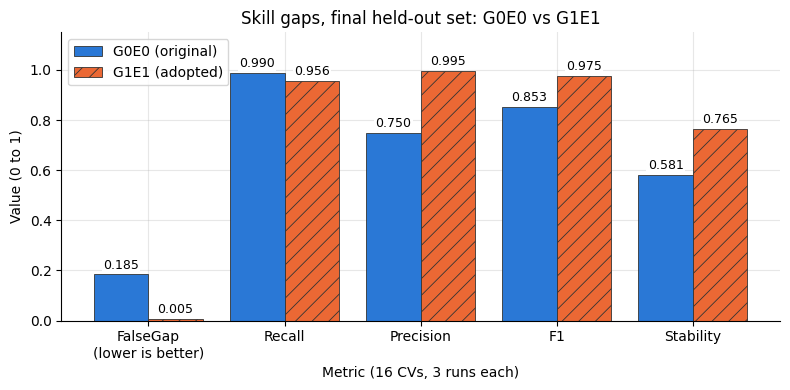

In words, G0E0 -> G1E1 on all 16 CVs: FalseGap 0.185 -> 0.005, precision 0.750 -> 0.995, recall 0.990 -> 0.956 (change -0.033; rule: not more than 0.05 lower).


,career goal,goal seen in development,FalseGap G0E0,FalseGap G1E1,difference
CV,,,,,
ho_01,cybersecurity analyst,yes,0.000,0.000,0.000
ho_02,cybersecurity analyst,yes,0.100,0.000,-0.100
ho_03,data analyst,yes,0.476,0.083,-0.393
ho_04,data analyst,yes,0.116,0.000,-0.116
ho_05,software engineer,no,0.000,0.000,0.000
ho_06,software engineer,no,0.143,0.000,-0.143
ho_07,cloud devops engineer,no,0.178,0.000,-0.178
ho_08,network engineer,no,0.222,0.000,-0.222
ho_09,ai ml engineer,no,0.241,0.000,-0.241


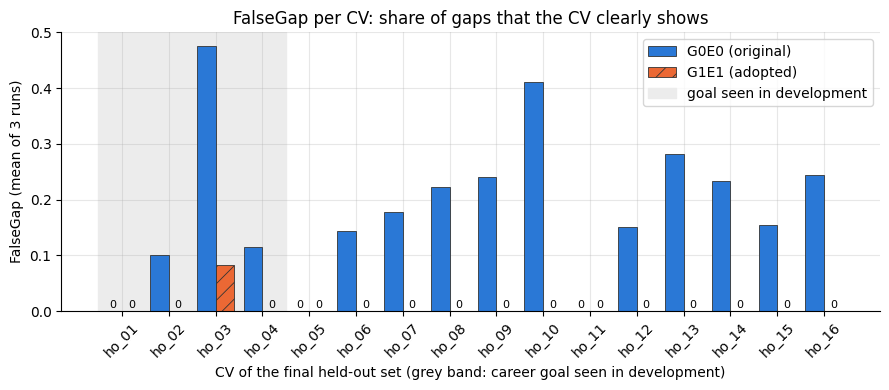

A "0" with no bar means 0.000. G1E1 is 0 on 15 of 16 CVs; G0E0 is 0 on 3 of 16 and above 0 on the other 13.


**2. Skill gaps: final held-out measurement: 38 PASS, 0 FAIL, 0 SKIPPED.**

In [9]:
print('Manifest name of the final set:', repr(FINAL['gs']['manifest'].get('set')),
      '| note present in scores.txt:', 'yes' if FINAL_TXT['not_heldout_note'] else 'no')

# ---- chart 1: the main metrics, all CVs
names = ['falseGap', 'recall', 'precision', 'f1', 'stability']
labels = ['FalseGap\n(lower is better)', 'Recall', 'Precision', 'F1', 'Stability']
values = {arm: [FINAL['scores']['all CVs'][arm][m] for m in names] for arm in ('G0E0', 'G1E1')}
display(pd.DataFrame(values, index=pd.Index([METRIC_LABELS[m] for m in names], name='metric (all 16 CVs)')).round(3)
        .rename(columns={'G0E0': 'G0E0 (original)', 'G1E1': 'G1E1 (adopted)'}))
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(names))
b1 = ax.bar(x - 0.2, values['G0E0'], 0.4, label='G0E0 (original)', **OLD_BAR)
b2 = ax.bar(x + 0.2, values['G1E1'], 0.4, label='G1E1 (adopted)', **NEW_BAR)
bar_labels(ax, b1); bar_labels(ax, b2)
ax.set_xticks(x, labels)
ax.set_ylim(0, 1.15)
ax.set_xlabel('Metric (16 CVs, 3 runs each)')
ax.set_ylabel('Value (0 to 1)')
ax.set_title('Skill gaps, final held-out set: G0E0 vs G1E1')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()
print(f"In words, G0E0 -> G1E1 on all 16 CVs: FalseGap {values['G0E0'][0]:.3f} -> {values['G1E1'][0]:.3f}, precision "
      f"{values['G0E0'][2]:.3f} -> {values['G1E1'][2]:.3f}, recall {values['G0E0'][1]:.3f} -> {values['G1E1'][1]:.3f} "
      f"(change {values['G1E1'][1] - values['G0E0'][1]:+.3f}; rule: not more than 0.05 lower).")

# ---- chart 2: FalseGap per CV
ids = [c['id'] for c in FINAL['gs']['cases']]
seen = [c['goal'] in SEEN_GOALS for c in FINAL['gs']['cases']]
per_cv = pd.DataFrame({
    'career goal': [c['goal'].replace('_', ' ') for c in FINAL['gs']['cases']],
    'goal seen in development': ['yes' if s else 'no' for s in seen],
    'FalseGap G0E0': [FINAL['scores']['all CVs']['G0E0']['by_case_fg'][i] for i in ids],
    'FalseGap G1E1': [FINAL['scores']['all CVs']['G1E1']['by_case_fg'][i] for i in ids],
}, index=pd.Index(ids, name='CV'))
per_cv['difference'] = per_cv['FalseGap G1E1'] - per_cv['FalseGap G0E0']
display(per_cv.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(ids))
for k in x[np.array(seen)]:
    ax.axvspan(k - 0.5, k + 0.5, color='#ececec', zorder=0)
ax.bar(x - 0.2, per_cv['FalseGap G0E0'], 0.4, label='G0E0 (original)', **OLD_BAR)
ax.bar(x + 0.2, per_cv['FalseGap G1E1'], 0.4, label='G1E1 (adopted)', **NEW_BAR)
for offset, col in ((-0.2, 'FalseGap G0E0'), (0.2, 'FalseGap G1E1')):
    for k, v in zip(x, per_cv[col]):
        if v == 0:                      # a zero draws no bar, so it is written
            ax.annotate('0', (k + offset, 0), ha='center', va='bottom', fontsize=8, xytext=(0, 1), textcoords='offset points')
ax.set_xticks(x, ids, rotation=45)
ax.set_xlabel('CV of the final held-out set (grey band: career goal seen in development)')
ax.set_ylabel('FalseGap (mean of 3 runs)')
ax.set_title('FalseGap per CV: share of gaps that the CV clearly shows')
handles, names_ = ax.get_legend_handles_labels()
ax.legend(handles + [matplotlib.patches.Patch(color='#ececec')], names_ + ['goal seen in development'])
plt.tight_layout()
plt.show()
zero_new = int((per_cv['FalseGap G1E1'] == 0).sum())
zero_old = int((per_cv['FalseGap G0E0'] == 0).sum())
print(f'A "0" with no bar means 0.000. G1E1 is 0 on {zero_new} of {len(ids)} CVs; G0E0 is 0 on {zero_old} of {len(ids)} '
      f'and above 0 on the other {len(ids) - zero_old}.')
section_result(SEC)

## 3. Skill gaps: first held-out round

**What was tested.** The same comparison with four versions: G0E0 (original), G0E1 (original gap step with single-skill market names), G1E1 (the candidate) and G2E1 (names first, then each checked against the CV).

**Data.** 16 other fictional CVs in `evaluation/skill_gaps/first_set/`, 3 runs per CV and version, answers in `evaluation/skill_gaps/first_run/raw/`. The reviewers' judgements are in `evaluation/skill_gaps/first_set/judgements/names.csv`. The `extraGoals` and `links` settings of `config.json` belong to other measurements and do not affect these scores.

**Metrics and rule.** As in Section 2; `tools/gap_eval/freeze.json` pinned the settings of this round before it ran.

**Result.** Only G1E1 met every rule: G0E1 did not lower FalseGap, and G2E1 lost too much recall (-0.068 against the limit of -0.05). This set was used during the quality checks that followed, so a new set (Section 2) was written for the final decision.

In [10]:
SEC = '3. Skill gaps: first held-out round'
t = time.time()
FIRST = score_gap_run('evaluation/skill_gaps/first_run')
first_txt = FIRST['run_dir'] / 'scores.txt'
FIRST_TXT = parse_gap_scores_txt(first_txt)
print(f"Test set {rel(FIRST['gs']['path'])}: {len(FIRST['gs']['cases'])} CVs, versions {', '.join(FIRST['arms'])}, "
      f"{FIRST['runs']} runs; reviewer judgements: {FIRST['gs']['names_rows']} rows. Scored in {time.time() - t:.1f} s.")
check_exact(SEC, 'names waiting for review (rows of review/names_review.csv)',
            len(read_csv(FIRST['run_dir'] / 'review' / 'names_review.csv')), 0,
            rel(FIRST['run_dir'] / 'review' / 'names_review.csv'), kind='count')

table_first, shown_first, largest_first = compare_gap_run(SEC, FIRST, splits_to_check=['all CVs'])
print("\nAll CVs: the main metrics, recomputed, next to the saved scores.json value (3 decimals):")
display(shown_first)
print(f'All {len(GAP_METRICS)} metrics of scores.json were compared for every split and version:')
show_table(largest_first)

print('\nComparison with the expected values:')
for arm, metrics in EXPECTED['gaps_first']['all CVs'].items():
    for metric, expected in metrics.items():
        check_close(SEC, f'all CVs, {arm}: {METRIC_LABELS[metric]}', FIRST['scores']['all CVs'][arm][metric], expected, 3)

print('\nDifferences, the six rules of every version and the decision, against the saved scores.txt:')
intervals_first, rules_first = compare_against(SEC, FIRST, FIRST_TXT, first_txt)
display(intervals_first.set_index(['version', 'difference against G0E0']))
print('Rules not met (every other rule is met, in the recomputation and in the saved output):')
display(rules_first[(rules_first['rule outcome (recomputed)'] != 'met') | (rules_first['rule outcome (saved)'] != 'met')]
        .set_index(['version', 'rule']))

Test set evaluation/skill_gaps/first_set: 16 CVs, versions G0E0, G0E1, G1E1, G2E1, 3 runs; reviewer judgements: 182 rows. Scored in 3.5 s.
PASS    names waiting for review (rows of review/names_review.csv): counted 0 | expected 0
PASS    all CVs, G0E0: all 15 metrics equal scores.json
        recomputed largest difference 1.1e-16 | expected at most 1e-9
PASS    all CVs, G0E1: all 15 metrics equal scores.json
        recomputed largest difference 1.1e-16 | expected at most 1e-9
PASS    all CVs, G1E1: all 15 metrics equal scores.json
        recomputed largest difference 1.1e-16 | expected at most 1e-9
PASS    all CVs, G2E1: all 15 metrics equal scores.json
        recomputed largest difference 0.0e+00 | expected at most 1e-9
PASS    unseen goals, G0E0: all 15 metrics equal scores.json
        recomputed largest difference 1.1e-16 | expected at most 1e-9
PASS    unseen goals, G0E1: all 15 metrics equal scores.json
        recomputed largest difference 1.1e-16 | expected at most 1e-9
PASS

G0E0 recomputed G0E0 saved G0E1 recomputed G0E1 saved G1E1 recomputed G1E1 saved G2E1 recomputed G2E1 saved
split   metric                                                                                                               
all CVs FalseGap            0.184      0.184           0.193      0.193           0.005      0.005           0.000      0.000
        Recall              0.973      0.973           0.992      0.992           0.932      0.932           0.905      0.905
        Precision           0.761      0.761           0.794      0.794           0.995      0.995           1.000      1.000
        F1                  0.854      0.854           0.882      0.882           0.962      0.962           0.950      0.950
        Stability           0.580      0.580           0.673      0.673           0.755      0.755           0.755      0.755
        gaps/run            6.417      6.417           6.979      6.979           4.938      4.938           4.583      4.583

All 15 metrics of scores.json were compared for every split and version:


split,version,metrics compared,largest difference
all CVs,G0E0,15,1.1e-16
all CVs,G0E1,15,1.1e-16
all CVs,G1E1,15,1.1e-16
all CVs,G2E1,15,0.0e+00
unseen goals,G0E0,15,1.1e-16
unseen goals,G0E1,15,1.1e-16
unseen goals,G1E1,15,2.2e-16
unseen goals,G2E1,15,2.2e-16
seen goals,G0E0,15,0.0e+00
seen goals,G0E1,15,1.1e-16



Comparison with the expected values:
PASS    all CVs, G0E0: FalseGap: recomputed 0.184 (full 0.184350) | expected 0.184
PASS    all CVs, G0E0: Recall: recomputed 0.973 (full 0.973264) | expected 0.973
PASS    all CVs, G0E1: FalseGap: recomputed 0.193 (full 0.192526) | expected 0.193
PASS    all CVs, G1E1: FalseGap: recomputed 0.005 (full 0.005208) | expected 0.005
PASS    all CVs, G1E1: Recall: recomputed 0.932 (full 0.931845) | expected 0.932
PASS    all CVs, G2E1: FalseGap: recomputed 0.000 (full 0.000000) | expected 0.000
PASS    all CVs, G2E1: Recall: recomputed 0.905 (full 0.904836) | expected 0.905

Differences, the six rules of every version and the decision, against the saved scores.txt:
PASS    G0E1 - G0E0, FalseGap, all CVs: difference and 95% interval
        recomputed +0.008 [-0.035, +0.053] (16 CVs) | expected +0.008 [-0.035, +0.053]
PASS    G0E1 - G0E0, FalseGap, unseen goals: difference and 95% interval
        recomputed +0.005 [-0.049, +0.064] (12 CVs) | expected +0.

recomputed                    saved
version difference against G0E0                                                           
G0E1    FalseGap, all CVs        +0.008 [-0.035, +0.053] (16 CVs)  +0.008 [-0.035, +0.053]
        FalseGap, unseen goals   +0.005 [-0.049, +0.064] (12 CVs)  +0.005 [-0.049, +0.064]
        Recall, all CVs          +0.018 [-0.008, +0.054] (16 CVs)  +0.018 [-0.008, +0.054]
G1E1    FalseGap, all CVs        -0.179 [-0.255, -0.111] (16 CVs)  -0.179 [-0.255, -0.111]
        FalseGap, unseen goals   -0.193 [-0.284, -0.112] (12 CVs)  -0.193 [-0.284, -0.112]
        Recall, all CVs          -0.041 [-0.074, -0.008] (16 CVs)  -0.041 [-0.074, -0.008]
G2E1    FalseGap, all CVs        -0.184 [-0.257, -0.117] (16 CVs)  -0.184 [-0.257, -0.117]
        FalseGap, unseen goals   -0.193 [-0.284, -0.112] (12 CVs)  -0.193 [-0.284, -0.112]
        Recall, all CVs          -0.068 [-0.105, -0.035] (16 CVs)  -0.068 [-0.105, -0.035]

Rules not met (every other rule is met, in the recomputation and in the saved output):


rule outcome (recomputed) rule outcome (saved)
version rule                                                                                                        
G0E1    FalseGap at least 0.05 lower on all CVs, interval excludes 0                    not met              not met
        FalseGap at least 0.05 lower on unseen goals (point estimate)                   not met              not met
G2E1    recall not more than 0.05 below G0E0                                            not met              not met

,G0E0,G0E1,G1E1,G2E1
metric (all 16 CVs),,,,
FalseGap,0.184,0.193,0.005,0.000
Recall,0.973,0.992,0.932,0.905


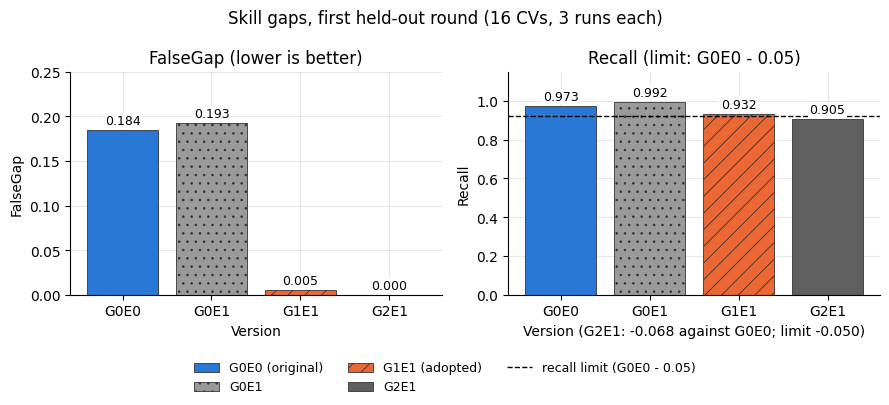

In words: FalseGap G0E0 0.184, G0E1 0.193, G1E1 0.005, G2E1 0.000. Recall against the limit 0.923: G0E0 0.973 (at or above), G0E1 0.992 (at or above), G1E1 0.932 (at or above), G2E1 0.905 (below).


**3. Skill gaps: first held-out round: 35 PASS, 0 FAIL, 0 SKIPPED.**

In [11]:
arms = FIRST['arms']
first_all = FIRST['scores']['all CVs']
colors = {'G0E0': BLUE, 'G0E1': GREYS[0], 'G1E1': ORANGE, 'G2E1': GREYS[1]}
hatches = {'G0E0': '', 'G0E1': '..', 'G1E1': '//', 'G2E1': ''}
suffix = {'G0E0': ' (original)', 'G1E1': ' (adopted)'}
tab = pd.DataFrame({arm: {'FalseGap': first_all[arm]['falseGap'], 'Recall': first_all[arm]['recall']} for arm in arms})
tab.index.name = 'metric (all 16 CVs)'
display(tab.round(3))
recall_limit = first_all['G0E0']['recall'] - 0.05
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, metric, title in zip(axes, ['FalseGap', 'Recall'], ['FalseGap (lower is better)', 'Recall (limit: G0E0 - 0.05)']):
    bars = ax.bar(arms, tab.loc[metric], color=[colors[a] for a in arms], **EDGE)
    for b, a in zip(bars, arms):
        b.set_hatch(hatches[a])
    bar_labels(ax, bars)
    if metric == 'Recall':
        limit = ax.axhline(recall_limit, color='black', ls='--', lw=1, zorder=2)
        ax.set_ylim(0, 1.15)
        drop = first_all['G2E1']['recall'] - first_all['G0E0']['recall']
        ax.set_xlabel(f'Version (G2E1: {drop:+.3f} against G0E0; limit -0.050)')
    else:
        ax.set_ylim(0, 0.25)
        ax.set_xlabel('Version')
    ax.set_ylabel(metric)
    ax.set_title(title)
handles = [matplotlib.patches.Patch(facecolor=colors[a], hatch=hatches[a], label=a + suffix.get(a, ''), **EDGE) for a in arms]
fig.legend(handles=handles + [limit], labels=[h.get_label() for h in handles] + ['recall limit (G0E0 - 0.05)'],
           loc='lower center', ncol=3, fontsize=9, frameon=False)
fig.suptitle('Skill gaps, first held-out round (16 CVs, 3 runs each)')
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()
print('In words: FalseGap ' + ', '.join(f"{a} {first_all[a]['falseGap']:.3f}" for a in arms)
      + f'. Recall against the limit {recall_limit:.3f}: '
      + ', '.join(f"{a} {first_all[a]['recall']:.3f} ({'at or above' if first_all[a]['recall'] >= recall_limit else 'below'})"
                  for a in arms) + '.')
section_result(SEC)

## 4. Opportunity recommender

**What was tested.** The ranking of opportunities (courses and programmes) for a user's skill gaps: the first recommender (frozen in `tools/recommender_eval/baseline_recommender.dart`) against the recommender the app uses (`lib/services/opportunity_recommender.dart`).

**Data.** 8 development test users (`test/fixtures/opportunity_eval_personas.json`) and 8 held-out test users (`..._heldout.json`). For each user, testers labelled relevant opportunities with a grade (1 relevant, 2 very relevant) and the gaps each one teaches. The tool ranks as if the date were 19 November 2026, so the rankings never change. Saved outputs (saved on 22 November 2026): `evaluation/recommender/development_2026-11-22.txt` and `heldout_2026-11-22.txt`.

**Metrics** (`tools/recommender_eval/ranking_metrics.dart`): *P@5* share of the first 5 results that are relevant; *nDCG@10* graded ranking quality of the first 10 (1.0 is the best possible order); *GapCov@10* share of the user's gaps taught by at least one of the first 10; *TopGapRank* rank of the first result that teaches the most demanded gap; *Ties@10* results among the first 10 that share their exact score with another; *Goal-only above gap* results that teach no gap but sit above one that does.

**Rule fixed in advance: none.** The new recommender is compared with the baseline; differences of about 0.02 are noise (README).

**How it is checked.** The pure-Python part reads the saved outputs and compares them with the expected values (these checks are marked *read*). When Dart is installed, the notebook also runs `tools/recommender_eval/evaluate_recommender.dart --top` (it writes no file and needs no AI service), checks that its output equals the saved one apart from the timing, reads the first 10 results of each system and recomputes P@5, nDCG@10, GapCov@10, Ties@10 and TopGapRank from the labels in Python. Opportunity titles are only used to find their ids; they are never printed.

**One limit of the Ties@10 recomputation.** The tool prints each score with 3 decimals, while `ranking_metrics.dart` compares the full scores (two scores tie when they differ by at most 1e-9). Two different scores that round to the same 3 decimals would count as a tie here only, so the recomputed Ties@10 can only over-count, never under-count. Those checks are labelled "from 3-decimal scores".

**Result.** On the held-out users, nDCG@10 rises from 0.696 to 0.806 and GapCov@10 from 0.609 to 0.750; the new recommender was adopted.

In [12]:
SEC = '4. Opportunity recommender'
PERSONA_FILES = {'held-out': 'test/fixtures/opportunity_eval_personas_heldout.json',
                 'development': 'test/fixtures/opportunity_eval_personas.json'}
SAVED_REC = {'held-out': Path('evaluation/recommender/heldout_2026-11-22.txt'),
             'development': Path('evaluation/recommender/development_2026-11-22.txt')}
REC_ARGS = {'held-out': ['--personas', PERSONA_FILES['held-out'], '--top', '--ablation'],
            'development': ['--top']}
HEADER = 'OPPORTUNITY RECOMMENDER EVALUATION'
REC_HEADER = re.compile(r'^(\S+)\s+\((.+?), (\d+) gaps, (\d+) labels, labels allow GapCov ([0-9.]+)\)$')
REC_ROW = re.compile(r'^  (P@5|nDCG@10|GapCov@10|Ties@10|TopGapRank|Goal-only above gap)\s+(-?[0-9.]+)\s+(-?[0-9.]+)\s+([+-]?[0-9.]+)$')
AVG_ROW = re.compile(r'^  (nDCG@10|GapCov@10|TopGapRank|P@5 \(sanity check\)|Ties@10|Goal-only above gap)\s+(-?[0-9.]+)\s+(-?[0-9.]+)\s+([+-]?[0-9.]+)$')
TOP_HEAD = re.compile(r'^  Top 10, (Baseline|New):$')
TOP_LINE = re.compile(r'^\s+(\d+)\. grade (\d)  score\s+(-?[0-9.]+)  (.*)  gaps=\[(.*)\]$')
SYSTEMS = ['Baseline', 'New']


def parse_rec_output(text):
    personas, tops, avg, ndcg = {}, {}, {}, {}
    cur = system = section = None
    for ln in text.splitlines():
        m = REC_HEADER.match(ln)
        if m:
            cur, system = m.group(1), None
            personas[cur] = dict(level=m.group(2), gaps=int(m.group(3)), labels=int(m.group(4)),
                                 allow=float(m.group(5)), metrics={})
            continue
        if ln and not ln.startswith(' '):
            cur = system = None
            section = ln
            continue
        if cur:
            m = TOP_HEAD.match(ln)
            if m:
                system = m.group(1)
                tops.setdefault(cur, {})[system] = []
                continue
            m = TOP_LINE.match(ln)
            if m and system:
                tops[cur][system].append(dict(rank=int(m.group(1)), grade=int(m.group(2)), score=float(m.group(3)),
                                              title=m.group(4), gaps=[g for g in m.group(5).split(', ') if g]))
                continue
            m = REC_ROW.match(ln)
            if m:
                personas[cur]['metrics'][m.group(1)] = (float(m.group(2)), float(m.group(3)))
        elif section and section.startswith('AVERAGE OVER'):
            m = AVG_ROW.match(ln)
            if m:
                avg[m.group(1).replace(' (sanity check)', '')] = (float(m.group(2)), float(m.group(3)))
        elif section and section.startswith('NDCG@10 PER PERSONA'):
            m = re.match(r'^  (\S+)\s+([0-9.]+)\s+([0-9.]+)\s+([+-][0-9.]+)$', ln)
            if m and m.group(1) != 'Average':
                ndcg[m.group(1)] = (float(m.group(2)), float(m.group(3)))
    return dict(personas=personas, tops=tops, avg=avg, ndcg=ndcg)


def comparable(text):
    """The output without the top-10 lists and the TIMING block (times change from run to run)."""
    out, in_timing = [], False
    for ln in text.splitlines():
        if ln.startswith('TIMING'):
            in_timing = True
        if not in_timing and not TOP_HEAD.match(ln) and not re.match(r'^\s+\d+\. grade \d+  score ', ln):
            out.append(ln.rstrip())
        if in_timing and not ln.strip():
            in_timing = False
    while out and not out[-1]:
        out.pop()
    return out


SAVED = {name: parse_rec_output(read_text(path)) for name, path in SAVED_REC.items()}
for name, parsed in SAVED.items():
    print(f"{rel(SAVED_REC[name])}: {len(parsed['personas'])} test users, average block with {len(parsed['avg'])} rows")

print('\nSaved outputs against the expected values (pure Python):')
for metric, (base, new) in EXPECTED['recommender']['held-out'].items():
    digits = 2 if metric in ('TopGapRank', 'Ties@10', 'Goal-only above gap') else 3
    saved_base, saved_new = SAVED['held-out']['avg'][metric]
    check_close(SEC, f'held-out average {metric}, baseline (saved output)', saved_base, base, digits, kind='read')
    check_close(SEC, f'held-out average {metric}, new (saved output)', saved_new, new, digits, kind='read')
for metric, (base, new) in EXPECTED['recommender']['development'].items():
    saved_base, saved_new = SAVED['development']['avg'][metric]
    check_close(SEC, f'development average {metric}, baseline (saved output)', saved_base, base, 3, kind='read')
    check_close(SEC, f'development average {metric}, new (saved output)', saved_new, new, 3, kind='read')
for pid, expected in EXPECTED['recommender']['held-out new nDCG@10'].items():
    check_close(SEC, f'held-out nDCG@10 of {pid}, new (saved output)', SAVED['held-out']['ndcg'][pid][1], expected, 3, kind='read')

print('\nInside each saved output, the averages of the whole-number metrics equal the mean of the 8 test users:')
for name, parsed in SAVED.items():
    pairs = []
    for metric in ('Ties@10', 'TopGapRank', 'Goal-only above gap'):
        for k, system in enumerate(SYSTEMS):
            per_user = mean(p['metrics'][metric][k] for p in parsed['personas'].values())
            pairs.append((metric, system, per_user, parsed['avg'][metric][k]))
    agree = sum(abs(a - b) <= 0.0005 for _, _, a, b in pairs)
    goal_only = [(a, b) for m, _, a, b in pairs if m == 'Goal-only above gap']
    check_true(SEC, f'{name}: printed averages of Ties@10, TopGapRank and Goal-only above gap equal the mean of the users',
               agree == len(pairs),
               f'{agree} of {len(pairs)} agree; Goal-only above gap {goal_only[0][0]:.3f} -> {goal_only[1][0]:.3f}',
               f'{len(pairs)} of {len(pairs)}; printed {goal_only[0][1]:.3f} -> {goal_only[1][1]:.3f}', rel(SAVED_REC[name]), kind='read')

# the persona guard of the matching measurement quotes today's recommender averages
guard_text = read_text('evaluation/matching/final_run/review/matching_scores_r2.txt')
for name, persona_file in PERSONA_FILES.items():
    quoted = [tuple(float(x) for x in m.groups()) for ln in guard_text.splitlines() if persona_file.split('/')[-1] + ':' in ln
              for m in [re.search(r'today ([0-9.]+) / ([0-9.]+) / ([0-9.]+) / ([0-9.]+)', ln)] if m]
    avg = SAVED[name]['avg']
    mine = (avg['nDCG@10'][1], avg['GapCov@10'][1], avg['P@5'][1], avg['TopGapRank'][1])
    check_true(SEC, f'{name}: "today" values quoted by the matching guard equal the new recommender averages',
               bool(quoted) and all(all(abs(a - b) <= 0.0005 for a, b in zip(q, mine)) for q in quoted),
               ' / '.join(f'{v:.3f}' for v in mine) + f' ({len(quoted)} lines)',
               ' / '.join(f'{v:.3f}' for v in quoted[0]) if quoted else 'missing',
               'evaluation/matching/final_run/review/matching_scores_r2.txt', kind='read')

evaluation/recommender/heldout_2026-11-22.txt: 8 test users, average block with 6 rows
evaluation/recommender/development_2026-11-22.txt: 8 test users, average block with 6 rows

Saved outputs against the expected values (pure Python):
PASS    held-out average nDCG@10, baseline (saved output): read 0.696 | expected 0.696
PASS    held-out average nDCG@10, new (saved output): read 0.806 | expected 0.806
PASS    held-out average GapCov@10, baseline (saved output): read 0.609 | expected 0.609
PASS    held-out average GapCov@10, new (saved output): read 0.750 | expected 0.750
PASS    held-out average P@5, baseline (saved output): read 0.850 | expected 0.850
PASS    held-out average P@5, new (saved output): read 0.975 | expected 0.975
PASS    held-out average TopGapRank, baseline (saved output): read 13.50 | expected 13.50
PASS    held-out average TopGapRank, new (saved output): read 1.50 | expected 1.50
PASS    held-out average Ties@10, baseline (saved output): read 7.25 | expected 7.25
PAS

The next cell runs `evaluate_recommender.dart --top` for both sets of test users and compares its output with the saved output; the cell after it recomputes the metrics of every user from the first 10 results and the labels.

In [13]:
catalogue = read_json('lib/assets/data/Masra_Opportunities.json')
ids_by_title, ids_by_loose_title = {}, {}
for o in catalogue:
    ids_by_title.setdefault(str(o.get('title', '')), []).append(str(o['id']))
    ids_by_loose_title.setdefault(' '.join(str(o.get('title', '')).split()).lower(), []).append(str(o['id']))
print(f"Catalogue lib/assets/data/Masra_Opportunities.json: {len(catalogue)} opportunities; "
      f"titles used by more than one opportunity: {sum(1 for v in ids_by_title.values() if len(v) > 1)}")


def is_missing(v):
    return v is None or (isinstance(v, float) and math.isnan(v))


def persona_labels(p):
    gaps = [str(g).strip() for g in (p.get('skillGaps') or []) if str(g).strip()]
    grades, teaches = {}, {}
    for lab in p.get('relevant') or []:
        oid = str(lab.get('id', ''))
        grades[oid] = int(lab['grade'])
        teaches[oid] = {key(str(t).strip()) for t in (lab.get('teaches') or []) if str(t).strip()}
    return gaps, grades, teaches


def gap_coverage(gaps, teaches, ids):
    taught = set()
    for i in ids:
        taught |= teaches.get(i, set())
    return sum(1 for g in gaps if key(g) in taught) / len(gaps) if gaps else 0.0


def ranking_metrics(gaps, grades, teaches, ids, scores):
    g = [grades.get(i, 0) for i in ids]
    dcg = lambda seq: sum((2 ** x - 1) / math.log2(k + 2) for k, x in enumerate(seq[:10]))
    ideal = dcg(sorted(grades.values(), reverse=True))
    top = key(gaps[0])
    top10 = scores[:10]
    return {
        'P@5': sum(1 for x in g[:5] if x >= 1) / 5,
        'nDCG@10': dcg(g) / ideal if ideal else 0.0,
        'GapCov@10': gap_coverage(gaps, teaches, ids[:10]),
        'Ties@10': sum(1 for a in range(len(top10))
                       if any(b != a and abs(top10[a] - top10[b]) <= 1e-9 for b in range(len(top10)))),
        'TopGapRank': next((k + 1 for k, i in enumerate(ids[:10]) if top in teaches.get(i, set())), None),
    }


def resolve_ids(items, grades, teaches, notes, where):
    ids = []
    for it in items:
        cands = ids_by_title.get(it['title']) or ids_by_loose_title.get(' '.join(it['title'].split()).lower()) or []
        if not cands:
            notes['missing'].append(f"{where}, rank {it['rank']}")
            ids.append(None)
            continue
        if len(cands) > 1:
            signatures = {(grades.get(c, 0), frozenset(teaches.get(c, set()))) for c in cands}
            if len(signatures) == 1:
                notes['same labels'].append(f"{where}, rank {it['rank']}: ids {' / '.join(cands)}")
            else:
                notes['ambiguous'].append(f"{where}, rank {it['rank']}: ids {' / '.join(cands)}")
                cands = [c for c in cands if grades.get(c, 0) == it['grade']] or cands
        ids.append(cands[0])
    return ids


REC_RUNS = {}
for name in ('held-out', 'development'):
    if not HAVE_DART:
        for what in ('tool run', 're-run equal to the saved output', 'titles found', 'printed grades',
                     'labels allow GapCov', 'per-user metrics'):
            skip(SEC, f'{name}: {what}', 'dart is not installed', source='evaluate_recommender.dart')
        continue
    args = ['dart', 'run', 'tools/recommender_eval/evaluate_recommender.dart'] + REC_ARGS[name]
    res = run_tool(args, timeout=900)
    print(f"\n$ {' '.join(args)}   ({res['seconds']:.0f} s, exit code {res['code']})")
    text = res['raw'].replace('\r\n', '\n')
    start = text.find(HEADER)
    warnings_found = [l for l in text.splitlines() if l.startswith('WARNING')]
    ok = res['code'] == 0 and start >= 0 and not warnings_found
    check_true(SEC, f'{name}: the tool ran, printed its header and no WARNING (no label dropped)', ok,
               f"exit {res['code']}, header {'found' if start >= 0 else 'missing'}, {len(warnings_found)} WARNING lines",
               'exit 0, header found, 0 WARNING lines', 'evaluate_recommender.dart', kind='run')
    if res['code'] != 0 or start < 0:
        print('First line of the error output:', safe_line(res['err'] or res['out']))
        continue
    before = [l for l in text[:start].splitlines() if l.strip()]
    if before:
        print(f'{len(before)} build lines printed before the header were ignored.')
    text = text[start:]
    now, saved = comparable(text), comparable(read_text(SAVED_REC[name]))
    first_diff = next((k for k in range(max(len(now), len(saved)))
                       if (now[k] if k < len(now) else '(no line)') != (saved[k] if k < len(saved) else '(no line)')), None)
    check_true(SEC, f'{name}: output of this run equals the saved output (without top-10 lists and TIMING)',
               first_diff is None, f'{len(now)} lines, ' + ('identical' if first_diff is None else f'first difference at line {first_diff + 1}'),
               f'{len(saved)} lines, identical', rel(SAVED_REC[name]), kind='run')
    if first_diff is not None:
        print('  now  :', safe_line(now[first_diff] if first_diff < len(now) else '(no line)'))
        print('  saved:', safe_line(saved[first_diff] if first_diff < len(saved) else '(no line)'))
    REC_RUNS[name] = parse_rec_output(text)

Catalogue lib/assets/data/Masra_Opportunities.json: 430 opportunities; titles used by more than one opportunity: 1
SKIPPED held-out: tool run: not run: dart is not installed | expected n/a
SKIPPED held-out: re-run equal to the saved output: not run: dart is not installed | expected n/a
SKIPPED held-out: titles found: not run: dart is not installed | expected n/a
SKIPPED held-out: printed grades: not run: dart is not installed | expected n/a
SKIPPED held-out: labels allow GapCov: not run: dart is not installed | expected n/a
SKIPPED held-out: per-user metrics: not run: dart is not installed | expected n/a
SKIPPED development: tool run: not run: dart is not installed | expected n/a
SKIPPED development: re-run equal to the saved output: not run: dart is not installed | expected n/a
SKIPPED development: titles found: not run: dart is not installed | expected n/a
SKIPPED development: printed grades: not run: dart is not installed | expected n/a
SKIPPED development: labels allow GapCov: not 

In [14]:
TIES_NOTE = ' (from 3-decimal scores)'
REC_RESULTS = {}
for name, parsed in REC_RUNS.items():
    personas = read_json(PERSONA_FILES[name])
    notes = {'missing': [], 'ambiguous': [], 'same labels': []}
    lines = grade_mismatch = 0
    allow_ok = []
    rows = []
    for p in personas:
        pid = p['id']
        gaps, grades, teaches = persona_labels(p)
        header = parsed['personas'][pid]
        allow = gap_coverage(gaps, teaches, list(grades))
        allow_ok.append(abs(allow - header['allow']) <= 0.005 + 1e-12)
        saved_metrics = SAVED[name]['personas'][pid]['metrics']
        for k, system in enumerate(SYSTEMS):
            items = parsed['tops'][pid][system]
            ids = resolve_ids(items, grades, teaches, notes, f'{pid}, {system}')
            lines += len(items)
            grade_mismatch += sum(1 for it, i in zip(items, ids) if i is None or grades.get(i, 0) != it['grade'])
            mine = ranking_metrics(gaps, grades, teaches, [i for i in ids if i is not None], [it['score'] for it in items])
            row = dict(set=name, user=pid, system=system)
            for metric in ('P@5', 'nDCG@10', 'GapCov@10', 'Ties@10', 'TopGapRank'):
                row[f'{metric} recomputed'] = mine[metric]
                row[f'{metric} saved'] = saved_metrics[metric][k]
            rows.append(row)
    table = pd.DataFrame(rows)
    REC_RESULTS[name] = table
    check_true(SEC, f'{name}: every title of the top-10 lists found in the catalogue, none ambiguous',
               not notes['missing'] and not notes['ambiguous'],
               f"{lines} lines, {len(notes['missing'])} not found, {len(notes['ambiguous'])} ambiguous",
               '160 lines, 0 not found, 0 ambiguous', 'lib/assets/data/Masra_Opportunities.json')
    for n in notes['missing'] + notes['ambiguous']:
        print('  ', n)
    if notes['same labels']:
        print(f"  {len(notes['same labels'])} lines show a title used by two ids with the same grade and the same "
              f"taught gaps for this user, so the metrics do not depend on which id it is:")
        for n in notes['same labels']:
            print('    ', n)
    check_true(SEC, f'{name}: printed grade equals the label grade on every top-10 line', grade_mismatch == 0,
               f'{lines - grade_mismatch} of {lines} lines agree', f'{lines} of {lines}', PERSONA_FILES[name])
    check_true(SEC, f'{name}: "labels allow GapCov" recomputed from the labels (2 decimals)', all(allow_ok),
               f'{sum(allow_ok)} of {len(allow_ok)} users agree', f'{len(allow_ok)} of {len(allow_ok)}', 'header lines of the output')

    for system in SYSTEMS:
        part = table[table['system'] == system]
        for metric in ('P@5', 'nDCG@10', 'GapCov@10', 'Ties@10', 'TopGapRank'):
            mine, saved = part[f'{metric} recomputed'].tolist(), part[f'{metric} saved'].tolist()
            if metric == 'TopGapRank':
                agree = [(not is_missing(m) and m == s) if s <= 10 else is_missing(m) for m, s in zip(mine, saved)]
            elif metric == 'Ties@10':
                agree = [m == s for m, s in zip(mine, saved)]
            else:
                agree = [abs(m - s) <= 0.0005 + 1e-12 for m, s in zip(mine, saved)]
            check_true(SEC, f'{name}, {system}: {metric}{TIES_NOTE if metric == "Ties@10" else ""} of each user, recomputed vs saved output',
                       all(agree),
                       f'{sum(agree)} of {len(agree)} users agree', f'{len(agree)} of {len(agree)}', rel(SAVED_REC[name]))

if REC_RESULTS:
    show = pd.concat(REC_RESULTS.values(), ignore_index=True)
    show['TopGapRank recomputed'] = show['TopGapRank recomputed'].map(lambda v: '>10' if is_missing(v) else int(v))
    for col in ('Ties@10 saved', 'TopGapRank saved', 'Ties@10 recomputed'):
        show[col] = show[col].astype(int)
    print('\nPer test user: recomputed in Python from the labels and the first 10 results, next to the saved output.')
    print('TopGapRank can only be recomputed up to rank 10; ">10" means none of the first 10 teaches the top gap.')
    display(show.set_index(['set', 'user', 'system']).round(3))

In [15]:
if 'held-out' in REC_RESULTS:
    t = REC_RESULTS['held-out']
    print('Recomputed held-out averages against the expected values:')
    for metric in ('P@5', 'nDCG@10', 'GapCov@10', 'Ties@10'):
        for k, system in enumerate(SYSTEMS):
            value = float(t[t['system'] == system][f'{metric} recomputed'].mean())
            check_close(SEC, f'held-out average {metric}, {system.lower()} (recomputed{" from 3-decimal scores" if metric == "Ties@10" else ""})', value,
                        EXPECTED['recommender']['held-out'][metric][k], 2 if metric == 'Ties@10' else 3)
    for k, system in enumerate(SYSTEMS):
        part = t[t['system'] == system]
        ranks = [None if is_missing(m) else m for m in part['TopGapRank recomputed']]
        if all(r is not None for r in ranks):
            check_close(SEC, f'held-out average TopGapRank, {system.lower()} (recomputed)', mean(ranks),
                        EXPECTED['recommender']['held-out']['TopGapRank'][k], 2)
        else:
            used = [r if r is not None else s for r, s in zip(ranks, part['TopGapRank saved'])]
            n_tool = sum(1 for r in ranks if r is None)
            check_close(SEC, f'held-out average TopGapRank, {system.lower()} (partly recomputed: {8 - n_tool} ranks '
                        f'recomputed, {n_tool} beyond rank 10 taken from the tool)', mean(used),
                        EXPECTED['recommender']['held-out']['TopGapRank'][k], 2)
else:
    skip(SEC, 'held-out averages recomputed from the top-10 lists', 'dart is not installed' if not HAVE_DART else 'the tool did not run', source='expected value', kind='recomputed')
if 'development' in REC_RESULTS:
    t = REC_RESULTS['development']
    print('\nRecomputed development averages against the expected values:')
    for metric in ('nDCG@10', 'GapCov@10'):
        for k, system in enumerate(SYSTEMS):
            check_close(SEC, f'development average {metric}, {system.lower()} (recomputed)',
                        float(t[t['system'] == system][f'{metric} recomputed'].mean()),
                        EXPECTED['recommender']['development'][metric][k], 3)
else:
    skip(SEC, 'development averages recomputed from the top-10 lists', 'dart is not installed' if not HAVE_DART else 'the tool did not run', source='expected value', kind='recomputed')

print('\nShown from the saved output only (not recomputed): "Goal-only above gap" needs the whole ranked list, '
      'the ablation needs the recommender itself, and TIMING depends on the computer.')

SKIPPED held-out averages recomputed from the top-10 lists: not run: dart is not installed | expected n/a
SKIPPED development averages recomputed from the top-10 lists: not run: dart is not installed | expected n/a

Shown from the saved output only (not recomputed): "Goal-only above gap" needs the whole ranked list, the ablation needs the recommender itself, and TIMING depends on the computer.


Held-out nDCG@10 per test user (saved output):


,baseline,new,change
held-out test user,,,
web developer,0.767,0.891,0.124
mobile developer,0.813,0.877,0.064
data scientist,0.721,0.958,0.237
data engineer,0.742,0.878,0.136
QA test engineer,0.862,0.947,0.085
systems administrator,0.381,0.612,0.231
business analyst,0.802,0.790,-0.012
IT project manager,0.480,0.498,0.018


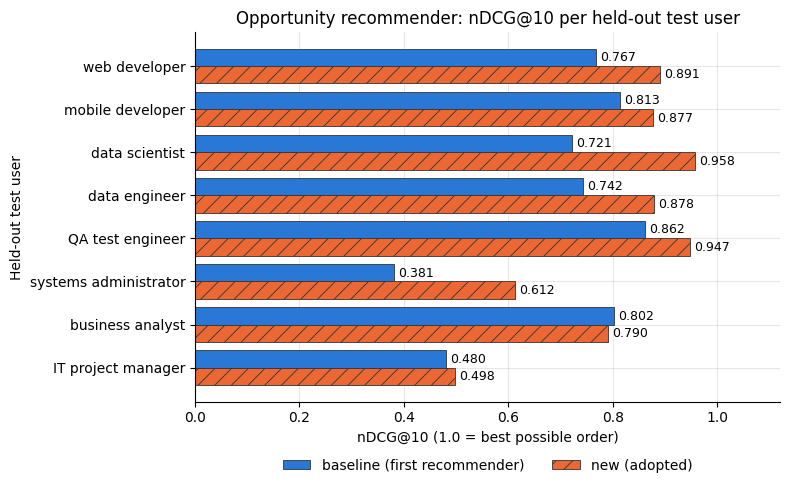

In words: the new recommender has a higher nDCG@10 for 7 of 8 held-out users; its lowest values are 0.498 (IT project manager) and 0.612 (systems administrator).
Held-out averages over 8 test users (saved output):


,baseline,new,change
metric,,,
nDCG@10,0.696,0.806,0.110
GapCov@10,0.609,0.750,0.141
P@5,0.850,0.975,0.125


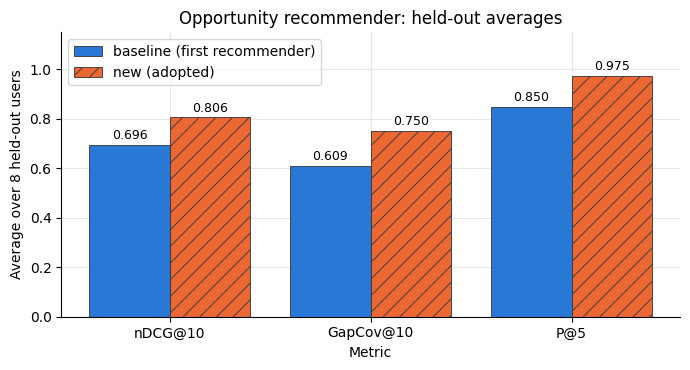

In words: on the held-out users, nDCG@10 rises from 0.696 to 0.806, GapCov@10 from 0.609 to 0.750 and P@5 from 0.850 to 0.975.


**4. Opportunity recommender: 28 PASS, 0 FAIL, 14 SKIPPED.**

In [16]:
def user_label(pid):
    """heldout_it_project_manager -> IT project manager"""
    words = pid.replace('heldout_', '').split('_')
    return ' '.join(w.upper() if w in ('it', 'qa') else w for w in words)


source = 'recomputed' if 'held-out' in REC_RESULTS else 'saved output'
users = list(EXPECTED['recommender']['held-out new nDCG@10'])
if source == 'recomputed':
    t = REC_RESULTS['held-out']
    nd = {s: t[t['system'] == s].set_index('user')['nDCG@10 recomputed'] for s in SYSTEMS}
else:
    nd = {s: pd.Series({u: SAVED['held-out']['ndcg'][u][k] for u in users}) for k, s in enumerate(SYSTEMS)}
per_user = pd.DataFrame({'baseline': [nd['Baseline'][u] for u in users], 'new': [nd['New'][u] for u in users]},
                        index=pd.Index([user_label(u) for u in users], name='held-out test user'))
per_user['change'] = per_user['new'] - per_user['baseline']
print(f'Held-out nDCG@10 per test user ({source}):')
display(per_user.round(3))
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(per_user))
# the baseline is the upper bar of each pair, as in the legend
r1 = ax.barh(y - 0.2, per_user['baseline'], 0.4, label='baseline (first recommender)', **OLD_BAR)
r2 = ax.barh(y + 0.2, per_user['new'], 0.4, label='new (adopted)', **NEW_BAR)
for bars in (r1, r2):
    for b in bars:
        ax.annotate(f'{b.get_width():.3f}', (b.get_width(), b.get_y() + b.get_height() / 2), va='center', ha='left',
                    fontsize=9, xytext=(3, 0), textcoords='offset points')
ax.set_yticks(y, per_user.index)
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.set_xlabel('nDCG@10 (1.0 = best possible order)')
ax.set_ylabel('Held-out test user')
ax.set_title('Opportunity recommender: nDCG@10 per held-out test user')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
plt.show()
better = int((per_user['change'] > 0).sum())
print(f"In words: the new recommender has a higher nDCG@10 for {better} of {len(per_user)} held-out users; its lowest values "
      f"are {per_user['new'].min():.3f} ({per_user['new'].idxmin()}) and "
      f"{per_user['new'].nsmallest(2).iloc[1]:.3f} ({per_user['new'].nsmallest(2).index[1]}).")

avg_rows = {}
for metric in ('nDCG@10', 'GapCov@10', 'P@5'):
    if source == 'recomputed':
        avg_rows[metric] = [float(t[t['system'] == s][f'{metric} recomputed'].mean()) for s in SYSTEMS]
    else:
        avg_rows[metric] = list(SAVED['held-out']['avg'][metric])
avg_table = pd.DataFrame(avg_rows, index=['baseline', 'new']).T
avg_table['change'] = avg_table['new'] - avg_table['baseline']
avg_table.index.name = 'metric'
print(f'Held-out averages over 8 test users ({source}):')
display(avg_table.round(3))
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(avg_table))
b1 = ax.bar(x - 0.2, avg_table['baseline'], 0.4, label='baseline (first recommender)', **OLD_BAR)
b2 = ax.bar(x + 0.2, avg_table['new'], 0.4, label='new (adopted)', **NEW_BAR)
bar_labels(ax, b1); bar_labels(ax, b2)
ax.set_xticks(x, avg_table.index)
ax.set_ylim(0, 1.15)
ax.set_xlabel('Metric')
ax.set_ylabel('Average over 8 held-out users')
ax.set_title('Opportunity recommender: held-out averages')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()
print(f"In words: on the held-out users, nDCG@10 rises from {avg_table.loc['nDCG@10', 'baseline']:.3f} to "
      f"{avg_table.loc['nDCG@10', 'new']:.3f}, GapCov@10 from {avg_table.loc['GapCov@10', 'baseline']:.3f} to "
      f"{avg_table.loc['GapCov@10', 'new']:.3f} and P@5 from {avg_table.loc['P@5', 'baseline']:.3f} to "
      f"{avg_table.loc['P@5', 'new']:.3f}.")

GLANCE['recommender'] = {
    'experiment': 'Opportunity recommender (8 held-out users)',
    'compared': 'baseline vs new recommender',
    'main number, earlier -> new': f"nDCG@10 {avg_table.loc['nDCG@10', 'baseline']:.3f} -> {avg_table.loc['nDCG@10', 'new']:.3f}; "
                                   f"GapCov@10 {avg_table.loc['GapCov@10', 'baseline']:.3f} -> {avg_table.loc['GapCov@10', 'new']:.3f} ({source})",
    'rule outcome': 'no rule fixed in advance; differences of about 0.02 are noise',
    'decision': 'new recommender adopted (as recorded)',
}
section_result(SEC)

## 5. Matching by meaning, not adopted

**What was tested.** Whether linking skill gaps to certifications and opportunities by meaning (B and B-opp: typed skill links from the AI service with a support check) finds teaching items better than today's word matching (A0). L1g is a word-matching control.

**Names in the saved output.** The score output names each approach by its settings (`tools/gap_eval/approaches.dart`):

| Short name | Name in the saved output | Meaning |
|---|---|---|
| A0 | `A0` | today's word matching and synonym table, no links |
| B | `B/10/10/bt` | typed links; support threshold 0.10 for opportunities and 0.10 for certifications; `bt`: a term of two or more words counts as evidence |
| B-opp | `B/10/10/bt-opp` | B for opportunities only; certifications keep A0 |
| L1 | `L1` | word control: every word link counts (reported only) |
| L1g | `L1g/10/10` | word control with the same support check (the control of rule 7.6) |
| L1g-opp | `L1g/10/05-opp` | L1g for opportunities only (threshold 0.10; the 0.05 for certifications is not used) |

**Data.** 61 decision names (skill gaps) over 13 career goals. For each name, the items the approaches proposed were pooled and graded blind: 0 does not teach it, 1 teaches it, 2 teaches it well (`evaluation/matching/final_run/judgements/teaching.csv`, 618 pairs). A second grader graded 124 of them (`teaching_second.csv`).

**Metrics.** *TeachHit@5*: share of the teachable names for which at least one of the first 5 attributed items teaches it; each name's value is the mean over its link runs, and the reported number is the mean of the two catalogues. *AttribPrec@5* is pooled over names (micro): each name's link runs together weigh 1, and the taught attributions in the first 5 are divided by all graded attributions in the first 5 (rule 7.2 c).

**Rule fixed in advance** (`tools/gap_eval/decision_rule_r2.txt`): among other guards, AttribPrec@5 must be at least 0.70 in each catalogue (rule 7.2 c), and TeachHit@5 must beat A0 by at least 0.10 with a 95% interval above 0 (rule 7.3). The timing guard (rule 7.2 d) compares speed ratios (the candidate's time divided by today's recommender's time), measured with the Dart evaluation script on the development computer, not times on a phone; it is shown, not recomputed.

**What is recomputed.** The scoring tool refuses to run on today's code, because two app files changed after the measurement (README). So the notebook (a) checks that the saved grades and the saved score output still have the SHA-256 values recorded in `tools/rerun_evaluations.dart`, (b) recomputes the graded pairs and the rater agreement (Cohen's kappa) from the two grade files, and (c) recomputes B's AttribPrec@5 and TeachHit@5 from the attribution lists saved in the score output and the grades. This recomputes the metric from the saved lists; it does not re-run the matching. A0's numbers are read from the saved output.

**Result.** B raised TeachHit@5 from 0.163 to 0.457 but its AttribPrec@5 was 0.691 for opportunities and 0.661 for certifications, below the 0.70 guard, so no candidate met the rules and A0 stays.

In [17]:
SEC = '5. Matching by meaning, not adopted'
MATCH = Path('evaluation/matching/final_run')
scores_path = MATCH / 'review' / 'matching_scores_r2.txt'
recorded = dict(re.findall(r"'(evaluation/matching/[^']+)':\s*'([0-9a-f]{64})'", read_text('tools/rerun_evaluations.dart'), flags=re.S))
check_exact(SEC, 'SHA-256 values recorded in tools/rerun_evaluations.dart', len(recorded), 3, 'tools/rerun_evaluations.dart',
            kind='count')
for path, recorded_hash in recorded.items():
    now = sha256(path)
    check_true(SEC, f'SHA-256 of {path}', now == recorded_hash, now[:16] + '...', recorded_hash[:16] + '...',
               'tools/rerun_evaluations.dart', kind='fingerprint')

first_rows = read_csv(MATCH / 'judgements' / 'teaching.csv')
second_rows = read_csv(MATCH / 'judgements' / 'teaching_second.csv')


def grade_of(row):
    g = (row.get('grade') or '').strip()
    return int(g) if re.fullmatch(r'[+-]?\d+', g) and 0 <= int(g) <= 2 else None


def read_grades(rows):
    """(goal, gap key, item type, item id) -> the first grade, as evaluate_matching.dart reads a sheet."""
    grades = {}
    for r in rows:
        g = grade_of(r)
        if g is not None:
            grades.setdefault((r['career_goal_id'], key(r['gap']), r['item_type'], r['item_id']), g)
    return grades


FIRST_GRADES = read_grades(first_rows)
SECOND_GRADES = read_grades(second_rows)
graded_rows = sum(1 for r in first_rows if grade_of(r) is not None)
print(f'teaching.csv: {len(first_rows)} rows, {graded_rows} with a grade 0-2, {len(FIRST_GRADES)} distinct pairs; '
      f'teaching_second.csv: {len(second_rows)} rows.')
check_exact(SEC, 'graded pairs in teaching.csv', len(FIRST_GRADES), EXPECTED['matching']['pairs'], 'expected value')
saved_pairs = int(re.search(r'^Grades: (\d+) graded pairs', read_text(scores_path), re.M).group(1))
check_exact(SEC, 'graded pairs in teaching.csv, against the "Grades:" line of the saved score output', len(FIRST_GRADES),
            saved_pairs, rel(scores_path))
dist = {g: sum(1 for v in FIRST_GRADES.values() if v == g) for g in (0, 1, 2)}
print(f'Grades of the first grader: 0 (does not teach it) {dist[0]}, 1 (teaches it) {dist[1]}, 2 (teaches it well) {dist[2]}.')


def cohen_kappa(a, b, weighted=False):
    """Port of cohenKappa in tools/gap_eval/eval_support.dart."""
    if not a or len(a) != len(b):
        return math.nan
    labels = sorted(set(a) | set(b))
    if len(labels) < 2:
        return 1.0
    n, span = len(a), labels[-1] - labels[0]
    w = (lambda x, y: 1 - abs(x - y) / span) if weighted else (lambda x, y: 1.0 if x == y else 0.0)
    observed = sum(w(x, y) for x, y in zip(a, b)) / n
    expected = sum((a.count(x) / n) * (b.count(y) / n) * w(x, y) for x in labels for y in labels)
    return 1.0 if expected >= 1 else (observed - expected) / (1 - expected)


pairs = [(FIRST_GRADES[k], g) for k, g in SECOND_GRADES.items() if k in FIRST_GRADES]
first, second = [p[0] for p in pairs], [p[1] for p in pairs]
check_exact(SEC, 'pairs graded by both graders', len(pairs), EXPECTED['matching']['second_pairs'], 'expected value')
kappa = cohen_kappa([int(g >= 1) for g in first], [int(g >= 1) for g in second])
kappa_w = cohen_kappa(first, second, weighted=True)
check_close(SEC, 'Cohen\'s kappa on "graded at least 1"', kappa, EXPECTED['matching']['kappa'], 3)
check_close(SEC, "Cohen's kappa, linear weights on the grades 0, 1, 2", kappa_w, EXPECTED['matching']['kappa_weighted'], 3)
saved_kappa = re.search(r"Cohen's kappa ([0-9.]+) on .*?, ([0-9.]+) weighted", read_text(scores_path))
check_true(SEC, 'both kappas equal the RATER AGREEMENT line of the saved score output',
           abs(kappa - float(saved_kappa.group(1))) <= 0.0005 and abs(kappa_w - float(saved_kappa.group(2))) <= 0.0005,
           f'{kappa:.3f} and {kappa_w:.3f}', f'{saved_kappa.group(1)} and {saved_kappa.group(2)}', rel(scores_path))
agreement = pd.crosstab(pd.Series(first, name='first grader (teaching.csv)'),
                        pd.Series(second, name='second grader (teaching_second.csv)')).reindex(index=[0, 1, 2], columns=[0, 1, 2], fill_value=0)
print('\nAgreement table (rows: first grader; columns: second grader; grades 0, 1, 2):')
display(agreement)

PASS    SHA-256 values recorded in tools/rerun_evaluations.dart: counted 3 | expected 3
PASS    SHA-256 of evaluation/matching/final_run/judgements/teaching.csv
        found e0575cad5858ad93... | expected e0575cad5858ad93...
PASS    SHA-256 of evaluation/matching/final_run/judgements/teaching_second.csv
        found 3444e1802b5b963d... | expected 3444e1802b5b963d...
PASS    SHA-256 of evaluation/matching/final_run/review/matching_scores_r2.txt
        found 12b4362684cbc61f... | expected 12b4362684cbc61f...
teaching.csv: 618 rows, 618 with a grade 0-2, 618 distinct pairs; teaching_second.csv: 124 rows.
PASS    graded pairs in teaching.csv: recomputed 618 | expected 618
PASS    graded pairs in teaching.csv, against the "Grades:" line of the saved score output
        recomputed 618 | expected 618
Grades of the first grader: 0 (does not teach it) 413, 1 (teaches it) 132, 2 (teaches it well) 73.
PASS    pairs graded by both graders: recomputed 124 | expected 124
PASS    Cohen's kappa on

second grader (teaching_second.csv),0,1,2
first grader (teaching.csv),,,
0,77,9,0
1,0,21,2
2,0,1,14


The next cell reads B's saved attribution lists (the first 5 items of every link run), looks up the grade of each item in `teaching.csv` and recomputes B's AttribPrec@5 and TeachHit@5. The saved scores of the other approaches follow it.

In [18]:
lines = read_text(scores_path).splitlines()
a0 = next(i for i, l in enumerate(lines) if l.startswith('ATTRIBUTIONS OF B/10/10/bt'))
a1 = next(i for i, l in enumerate(lines) if l.startswith('RATER AGREEMENT'))
ITEM_RE = re.compile(r'(.+?) \[(\d|\?)\](?:; |$)')
entries, cur, unparsed = [], None, 0
for ln in lines[a0 + 1:a1]:
    if not ln.strip():
        continue
    if ln.startswith('  ') and not ln.startswith('    '):
        parts = [p.strip() for p in ln.strip().split(' | ')]
        cur = dict(goal=parts[0], gap=parts[1], type=parts[2],
                   note_not_teachable=len(parts) > 3 and parts[3] == 'no pooled item teaches it', runs=[])
        entries.append(cur)
        continue
    m = re.match(r'^    run (\d+): (.*)$', ln)
    if m and cur is not None:
        body = m.group(2)
        items = [] if body == '(nothing)' else ITEM_RE.findall(body)
        if items and '; '.join(f'{t} [{b}]' for t, b in items) != body:
            unparsed += 1
        cur['runs'].append(items)
    else:
        unparsed += 1

# grade of an attributed item: from teaching.csv by (goal, gap key, item type, item title)
grades_by_title = {}
for r in first_rows:
    g = grade_of(r)
    if g is not None:
        grades_by_title.setdefault((r['career_goal_id'], key(r['gap']), r['item_type'], r['item_title']), set()).add(g)
teachable = {(k[0], k[1], k[2]) for k, g in FIRST_GRADES.items() if g >= 1}

bracket_mismatch = ambiguous = items_total = flag_mismatch = 0
for e in entries:
    e['teachable'] = (e['goal'], key(e['gap']), e['type']) in teachable
    flag_mismatch += int(e['teachable'] == e['note_not_teachable'])
    graded_runs = []
    for run in e['runs']:
        gs_ = []
        for title, bracket in run:
            items_total += 1
            found = grades_by_title.get((e['goal'], key(e['gap']), e['type'], title), set())
            if len(found) > 1:
                ambiguous += 1
            g = min(found) if len(found) == 1 else None
            if (str(g) if g is not None else '?') != bracket:
                bracket_mismatch += 1
            gs_.append(g)
        graded_runs.append(gs_)
    n = len(graded_runs) or 1
    e['taught'] = sum(sum(1 for g in r if g is not None and g >= 1) for r in graded_runs) / n
    e['counted'] = sum(sum(1 for g in r if g is not None) for r in graded_runs) / n
    e['hit'] = sum(1 for r in graded_runs if any(g is not None and g >= 1 for g in r)) / n
    e['uncovered'] = sum(1 for r in graded_runs if not r) / n

print(f'{len(entries)} (name, catalogue) entries with {sum(len(e["runs"]) for e in entries)} link runs and '
      f'{items_total} attributed items (first 5 per run).')
check_exact(SEC, 'attribution lines that could not be read', unparsed, 0, rel(scores_path), kind='count')
check_true(SEC, 'grade looked up in teaching.csv equals the bracket of the saved list, for every item',
           bracket_mismatch == 0 and ambiguous == 0, f'{items_total - bracket_mismatch} of {items_total} agree, {ambiguous} ambiguous titles',
           f'{items_total} of {items_total}', 'teaching.csv')
check_true(SEC, 'teachable names from teaching.csv agree with the "no pooled item teaches it" notes', flag_mismatch == 0,
           f'{len(entries) - flag_mismatch} of {len(entries)} agree', f'{len(entries)} of {len(entries)}', rel(scores_path))

B = {}
for typ in ('opportunity', 'certification'):
    es = [e for e in entries if e['type'] == typ]
    counted = sum(e['counted'] for e in es)
    # AttribPrec@5 is micro over names: each name's link runs weigh 1 in total (rule 7.2 c)
    B[typ] = dict(names=len(es), teachable=sum(e['teachable'] for e in es),
                  attrib=sum(e['taught'] for e in es) / counted if counted else math.nan, attributions=counted,
                  teachhit=mean(e['hit'] for e in es if e['teachable']),
                  false_uncov=mean(e['uncovered'] for e in es if e['teachable']))
B_teachhit = (B['opportunity']['teachhit'] + B['certification']['teachhit']) / 2

# the saved ALL NAMES table and the decision block
SHORT_NAME = {'A0': 'A0', 'L1': 'L1', 'B/10/10/bt': 'B', 'B/10/10/bt-opp': 'B-opp',
               'L1g/10/10': 'L1g', 'L1g/10/05-opp': 'L1g-opp'}
i = next(k for k, l in enumerate(lines) if l.startswith('ALL NAMES'))
cols = ['TeachHit@5', 'TeachHit@5 opp', 'TeachHit@5 cert', 'AttribPrec@5 opp', 'n opp (rounded)', 'AttribPrec@5 cert',
        'n cert (rounded)', 'FalseUncov opp', 'FalseUncov cert', 'ungraded']
WHOLE = {'n opp (rounded)', 'n cert (rounded)', 'ungraded'}     # printed as whole numbers in the saved table
saved_rows = {}
for ln in lines[i + 2:]:
    if not ln.strip() or ln.strip().startswith('Teachable'):
        break
    tok = ln.split()
    saved_rows[tok[0]] = {c: (None if x == 'n/a' else (int(x) if c in WHOLE else float(x))) for c, x in zip(cols, tok[1:])}
saved_table = pd.DataFrame(saved_rows).T[cols]
for c in cols:
    saved_table[c] = saved_table[c].astype('Int64' if c in WHOLE else 'float64')
teachable_line = re.search(r'Teachable hole names: (\d+) for opportunities, (\d+) for certifications', '\n'.join(lines[i:i + 12]))
dec_start = next(k for k, l in enumerate(lines) if l.startswith('DECISION RULES'))
dec_end = next(k for k, l in enumerate(lines) if l.startswith('DECISION:'))
blocks, name = {}, None
for ln in lines[dec_start + 1:dec_end]:
    m = re.match(r'^  (\S+): TeachHit@5 against A0 (.*)$', ln)
    if m:
        name = m.group(1)
        blocks[name] = dict(difference=m.group(2).strip(), lines=[], rules={})
        continue
    if name:
        blocks[name]['lines'].append(ln.strip())
        m = re.match(r'^\s+(pass|FAIL)\s+(.*)', ln)
        if m:
            blocks[name]['rules'][m.group(2).strip()] = m.group(1) == 'pass'
saved_attrib = {typ: re.search(rf'AttribPrec@5 {label} ([0-9.]+) on ([0-9.]+) graded', '\n'.join(blocks['B/10/10/bt']['lines']))
                for typ, label in (('opportunity', 'opportunities'), ('certification', 'certifications'))}

print('\nB (B/10/10/bt) recomputed from the saved attribution lists:')
sb = saved_table.loc['B/10/10/bt']
check_close(SEC, 'B: AttribPrec@5, opportunities', B['opportunity']['attrib'], EXPECTED['matching']['B_attrib_opp'], 3)
check_close(SEC, 'B: AttribPrec@5, certifications', B['certification']['attrib'], EXPECTED['matching']['B_attrib_cert'], 3)
for typ in ('opportunity', 'certification'):
    check_close(SEC, f'B: graded attributions behind AttribPrec@5, {typ}', B[typ]['attributions'],
                float(saved_attrib[typ].group(2)), 1, rel(scores_path))
check_close(SEC, 'B: TeachHit@5 (mean of the two catalogues)', B_teachhit, EXPECTED['matching']['B_teachhit'], 3)
check_close(SEC, 'B: TeachHit@5, opportunities', B['opportunity']['teachhit'], sb['TeachHit@5 opp'], 3, rel(scores_path))
check_close(SEC, 'B: TeachHit@5, certifications', B['certification']['teachhit'], sb['TeachHit@5 cert'], 3, rel(scores_path))
check_close(SEC, 'B: FalseUncovered, opportunities', B['opportunity']['false_uncov'], sb['FalseUncov opp'], 3, rel(scores_path))
check_close(SEC, 'B: FalseUncovered, certifications', B['certification']['false_uncov'], sb['FalseUncov cert'], 3, rel(scores_path))
check_exact(SEC, 'teachable names (opportunities, certifications)',
            (B['opportunity']['teachable'], B['certification']['teachable']),
            (int(teachable_line.group(1)), int(teachable_line.group(2))), rel(scores_path),
            show=lambda v: f'opportunities {v[0]}, certifications {v[1]}')

print('\nSaved scores of all approaches, all 61 names (read, not recomputed; the SHA-256 check above shows the file '
      'is unchanged). The (n) columns are printed rounded to whole numbers in the saved file; B\'s exact '
      f"number of graded opportunity attributions is {B['opportunity']['attributions']:.1f}.")
shown_saved = pd.DataFrame({c: ['n/a' if pd.isna(v) else (str(int(v)) if c in WHOLE else f'{v:.3f}') for v in saved_table[c]]
                            for c in cols},
                           index=pd.Index([f"{SHORT_NAME.get(k, k)} ({k})" if SHORT_NAME.get(k, k) != k else k
                                           for k in saved_table.index], name='approach (name in the saved output)'))
display(shown_saved)
check_close(SEC, 'A0: TeachHit@5 (saved score output)', saved_table.loc['A0', 'TeachHit@5'], EXPECTED['matching']['A0_teachhit'], 3,
            kind='read')
check_close(SEC, 'B: TeachHit@5 (saved score output)', saved_table.loc['B/10/10/bt', 'TeachHit@5'], EXPECTED['matching']['B_teachhit'], 3,
            kind='read')

120 (name, catalogue) entries with 430 link runs and 362 attributed items (first 5 per run).
PASS    attribution lines that could not be read: counted 0 | expected 0
PASS    grade looked up in teaching.csv equals the bracket of the saved list, for every item
        recomputed 362 of 362 agree, 0 ambiguous titles | expected 362 of 362
PASS    teachable names from teaching.csv agree with the "no pooled item teaches it" notes
        recomputed 120 of 120 agree | expected 120 of 120

B (B/10/10/bt) recomputed from the saved attribution lists:
PASS    B: AttribPrec@5, opportunities: recomputed 0.691 (full 0.691381) | expected 0.691
PASS    B: AttribPrec@5, certifications: recomputed 0.661 (full 0.661458) | expected 0.661
PASS    B: graded attributions behind AttribPrec@5, opportunity
        recomputed 71.3 (full 71.258333) | expected 71.3
PASS    B: graded attributions behind AttribPrec@5, certification
        recomputed 32.0 (full 32.000000) | expected 32.0
PASS    B: TeachHit@5 (mean 

,TeachHit@5,TeachHit@5 opp,TeachHit@5 cert,AttribPrec@5 opp,n opp (rounded),AttribPrec@5 cert,n cert (rounded),FalseUncov opp,FalseUncov cert,ungraded
approach (name in the saved output),,,,,,,,,,
A0,0.163,0.190,0.136,0.938,16,1.000,3,0.786,0.864,0
L1,0.512,0.524,0.500,0.465,127,0.314,86,0.405,0.364,0
B (B/10/10/bt),0.457,0.496,0.417,0.691,71,0.661,32,0.433,0.568,0
B-opp (B/10/10/bt-opp),0.316,0.496,0.136,0.691,71,1.000,3,0.433,0.864,0
L1g (L1g/10/10),0.557,0.524,0.591,0.644,90,0.600,45,0.429,0.409,0
L1g-opp (L1g/10/05-opp),0.330,0.524,0.136,0.644,90,1.000,3,0.429,0.864,0


PASS    A0: TeachHit@5 (saved score output): read 0.163 | expected 0.163
PASS    B: TeachHit@5 (saved score output): read 0.457 | expected 0.457


In [19]:
print('Rule 7.2 (c) evaluated in Python, and the decision:')
guard = EXPECTED['matching']['guard']
# the Python decision below covers exactly these two candidates, so the saved block must list exactly these
check_exact(SEC, 'candidates in the saved DECISION RULES block', set(blocks), {'B/10/10/bt', 'B/10/10/bt-opp'},
            rel(scores_path), kind='read')
mine_c = {typ: B[typ]['attributions'] == 0 or B[typ]['attrib'] >= guard for typ in B}
for typ, label in (('opportunity', 'opportunities'), ('certification', 'certifications')):
    rule = f'AttribPrec@5 at least 0.70 for {label}'
    check_exact(SEC, f'B: outcome of rule "{rule}"', outcome(mine_c[typ]),
                outcome(blocks['B/10/10/bt']['rules'][rule]), rel(scores_path))
# B-opp uses B's links for opportunities (and A0 for certifications), so it shares B's opportunity attributions
check_true(SEC, 'B-opp has the same opportunity AttribPrec@5 as B in the saved output',
           saved_table.loc['B/10/10/bt-opp', ['AttribPrec@5 opp', 'n opp (rounded)']].tolist()
           == saved_table.loc['B/10/10/bt', ['AttribPrec@5 opp', 'n opp (rounded)']].tolist(),
           f"{saved_table.loc['B/10/10/bt-opp', 'AttribPrec@5 opp']:.3f}", f"{saved_table.loc['B/10/10/bt', 'AttribPrec@5 opp']:.3f}",
           rel(scores_path), kind='read')
check_exact(SEC, 'B-opp: outcome of rule "AttribPrec@5 at least 0.70 for opportunities"', outcome(mine_c['opportunity']),
            outcome(blocks['B/10/10/bt-opp']['rules']['AttribPrec@5 at least 0.70 for opportunities']), rel(scores_path))
# 7.2 (c) for each candidate: B needs both catalogues; B-opp needs B's opportunities and its own certifications
# (A0's certification list, saved as met).
passes_72c = {'B/10/10/bt': mine_c['opportunity'] and mine_c['certification'],
              'B/10/10/bt-opp': mine_c['opportunity'] and blocks['B/10/10/bt-opp']['rules']['AttribPrec@5 at least 0.70 for certifications']}
print('Candidates that meet rule 7.2 (c):', ', '.join(SHORT_NAME[c] for c, ok in passes_72c.items() if ok) or 'none')
mine_decision = ('DECISION: no candidate passes these rules. A0 stays.' if not any(passes_72c.values())
                 else 'not decided here: a candidate meets 7.2 (c), and the other rules are not recomputed')
saved_decision = lines[dec_end].strip()
check_exact(SEC, 'decision line', mine_decision, saved_decision, rel(scores_path))
check_exact(SEC, 'decision as expected', saved_decision, EXPECTED['matching']['decision'], 'expected value', kind='read')

print('\nSaved decision block (read, not recomputed: the bootstrap of the difference, the persona guard and the timing '
      'guard). The timing guard compares speed ratios, candidate time / today\'s time, measured with the Dart script '
      'on the development computer.')
print('  B (B/10/10/bt): TeachHit@5 against A0', blocks['B/10/10/bt']['difference'])
show_table(pd.DataFrame([{'candidate': f'{SHORT_NAME[c]} ({c})', 'rule': r, 'rule outcome (saved)': outcome(ok)}
                         for c in blocks for r, ok in blocks[c]['rules'].items()]))

rule_text = read_text('tools/gap_eval/decision_rule_r2.txt')
quoted = [rule_text[rule_text.index('(c) AttribPrec@5'):rule_text.index('(d) Timing')].rstrip(),
          rule_text[rule_text.index('7.3 Adoption'):rule_text.index('7.4 Winner')].rstrip()]
print('\nThe two rules that decide here, quoted from tools/gap_eval/decision_rule_r2.txt:\n')
for part in quoted:
    print('\n'.join('  | ' + l for l in part.splitlines()))
    print()

GLANCE['matching'] = {
    'experiment': 'Matching by meaning (61 names)',
    'compared': 'A0 (word matching) vs B and B-opp (meaning links)',
    'main number, earlier -> new': f"TeachHit@5 {saved_table.loc['A0', 'TeachHit@5']:.3f} -> {B_teachhit:.3f}; "
                                   f"AttribPrec@5 of B {B['opportunity']['attrib']:.3f} (opp) and "
                                   f"{B['certification']['attrib']:.3f} (cert)",
    'rule outcome': 'rule 7.2 (c), AttribPrec@5 at least 0.70: ' + (
        'not met by any candidate' if not any(passes_72c.values()) else 'met by ' + ', '.join(c for c, ok in passes_72c.items() if ok)),
    'decision': 'A0 stays' if mine_decision.endswith('A0 stays.') else mine_decision,
}

Rule 7.2 (c) evaluated in Python, and the decision:
PASS    candidates in the saved DECISION RULES block
        read B/10/10/bt, B/10/10/bt-opp | expected B/10/10/bt, B/10/10/bt-opp
PASS    B: outcome of rule "AttribPrec@5 at least 0.70 for opportunities": recomputed not met | expected not met
PASS    B: outcome of rule "AttribPrec@5 at least 0.70 for certifications"
        recomputed not met | expected not met
PASS    B-opp has the same opportunity AttribPrec@5 as B in the saved output: read 0.691 | expected 0.691
PASS    B-opp: outcome of rule "AttribPrec@5 at least 0.70 for opportunities"
        recomputed not met | expected not met
Candidates that meet rule 7.2 (c): none
PASS    decision line
        recomputed DECISION: no candidate passes these rules. A0 stays. | expected DECISION: no candidate passes these rules. A0 stays.
PASS    decision as expected
        read DECISION: no candidate passes these rules. A0 stays. | expected DECISION: no candidate passes these rules. A0 sta

candidate,rule,rule outcome (saved)
B (B/10/10/bt),"TeachHit@5 beats A0 by at least 0.10, 95% interval above 0",met
B (B/10/10/bt),not below A0 for opportunities,met
B (B/10/10/bt),AttribPrec@5 at least 0.70 for opportunities,not met
B (B/10/10/bt),not below A0 for certifications,met
B (B/10/10/bt),AttribPrec@5 at least 0.70 for certifications,not met
B (B/10/10/bt),"7.2 (a) without links, the lists of today on both persona files",met
B (B/10/10/bt),"7.2 (b) persona guard (precision 3, tolerance 0): pass",met
B (B/10/10/bt),"7.2 (d) timing, amendment 1: medians of 5 separate runs at most 2.00 and 1.10, at full precision",met
B-opp (B/10/10/bt-opp),"TeachHit@5 beats A0 by at least 0.10, 95% interval above 0",met
B-opp (B/10/10/bt-opp),not below A0 for opportunities,met



The two rules that decide here, quoted from tools/gap_eval/decision_rule_r2.txt:

  | (c) AttribPrec@5 >= 0.70 for opportunities and >= 0.70 for certifications,
  |     on the decision names (micro over names, each name's link runs weigh 1
  |     in total, as round 1's scorer). A catalogue with no attribution at all
  |     passes. The guard is the point estimate, as in round 1; its 90%
  |     interval and the number of attributions behind it are printed next to
  |     it (reported, not a decision input).

  | 7.3 Adoption: TeachHit@5 on the decision names (mean of the two catalogues)
  | beats A0 by at least 0.10, with the 95% bootstrap interval of the difference
  | above 0 (10,000 resamples of names within (stratum, goal) **[V12]**, a name
  | with both catalogues as one unit, seed 20261121); and in neither catalogue
  | is the candidate below A0 (point estimate).



,"A0 (word matching, read)","B (meaning links, recomputed)"
TeachHit@5,,
both (mean),0.163,0.457
opportunities,0.190,0.496
certifications,0.136,0.417


,"A0 (word matching, read)","B (meaning links, recomputed)"
AttribPrec@5,,
opportunities,0.938,0.691
certifications,1.000,0.661


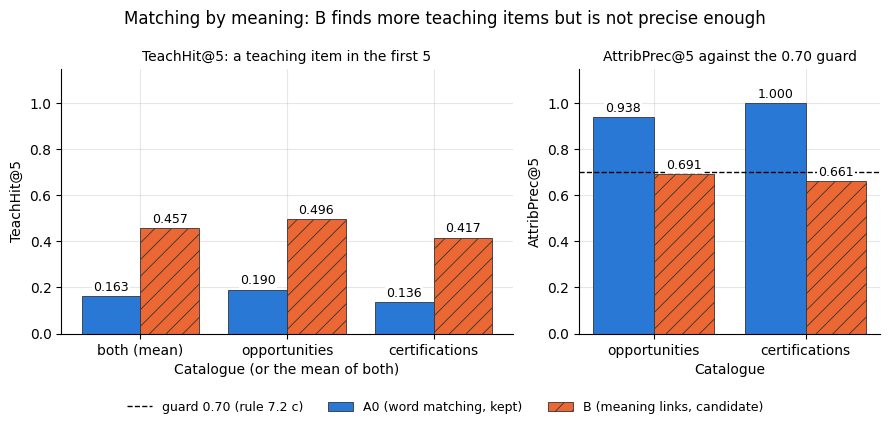

In words: B raises TeachHit@5 from 0.163 to 0.457; its AttribPrec@5 is 0.691 for opportunities (below the 0.70 guard) and 0.661 for certifications (below the guard).


**5. Matching by meaning, not adopted: 32 PASS, 0 FAIL, 0 SKIPPED.**

In [20]:
th = pd.DataFrame({'A0 (word matching, read)': [saved_table.loc['A0', c] for c in ('TeachHit@5', 'TeachHit@5 opp', 'TeachHit@5 cert')],
                   'B (meaning links, recomputed)': [B_teachhit, B['opportunity']['teachhit'], B['certification']['teachhit']]},
                  index=pd.Index(['both (mean)', 'opportunities', 'certifications'], name='TeachHit@5'))
ap = pd.DataFrame({'A0 (word matching, read)': [saved_table.loc['A0', 'AttribPrec@5 opp'], saved_table.loc['A0', 'AttribPrec@5 cert']],
                   'B (meaning links, recomputed)': [B['opportunity']['attrib'], B['certification']['attrib']]},
                  index=pd.Index(['opportunities', 'certifications'], name='AttribPrec@5'))
display(th.round(3))
display(ap.round(3))
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), gridspec_kw={'width_ratios': [3, 2]})
for ax, tab, title, ylabel, xlabel in ((axes[0], th, 'TeachHit@5: a teaching item in the first 5', 'TeachHit@5', 'Catalogue (or the mean of both)'),
                                       (axes[1], ap, 'AttribPrec@5 against the 0.70 guard', 'AttribPrec@5', 'Catalogue')):
    x = np.arange(len(tab))
    b1 = ax.bar(x - 0.2, tab.iloc[:, 0], 0.4, label='A0 (word matching, kept)', **OLD_BAR)
    b2 = ax.bar(x + 0.2, tab.iloc[:, 1], 0.4, label='B (meaning links, candidate)', **NEW_BAR)
    bar_labels(ax, b1); bar_labels(ax, b2)
    if tab is ap:
        ax.axhline(0.70, color='black', ls='--', lw=1, label='guard 0.70 (rule 7.2 c)', zorder=2)
    ax.set_xticks(x, tab.index)
    ax.set_ylim(0, 1.15)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)
handles, names_ = axes[1].get_legend_handles_labels()
fig.legend(handles, names_, loc='lower center', ncol=3, fontsize=9, frameon=False)
fig.suptitle('Matching by meaning: B finds more teaching items but is not precise enough')
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
side = lambda v: 'below' if v < 0.70 else 'at or above'
print(f"In words: B raises TeachHit@5 from {th.iloc[0, 0]:.3f} to {th.iloc[0, 1]:.3f}; its AttribPrec@5 is "
      f"{ap.iloc[0, 1]:.3f} for opportunities ({side(ap.iloc[0, 1])} the 0.70 guard) and {ap.iloc[1, 1]:.3f} for "
      f"certifications ({side(ap.iloc[1, 1])} the guard).")
section_result(SEC)

## 6. ATS review instructions, not adopted

**What was tested.** The review instructions of the CV Improvement Assistant: OLD, the text the app sends (`tools/ats_eval/old_improve_cv_prompt.txt`), against NEW, a rewritten text (`evaluation/ats_review/new_review_text.txt`).

**Data.** Four fictional held-out CVs (`evaluation/ats_review/heldout_set/`): ho_a, ho_b and ho_d with planted problems listed in answer keys (10, 10 and 6), and ho_c, a clean CV. 3 runs per CV and version, so 12 outputs per version. A grader graded every reported issue blind, under anonymous labels, and saved the grades with their SHA-256 before the labels were revealed (`evaluation/ats_review/grades/`).

**Metrics and rule fixed in advance** (`tools/ats_eval/decision_rule.txt`): NEW is adopted only if all five hold: (a) recall of planted problems at least 0.100 higher; (b) precision at most 0.030 lower; (c) no more invented facts and no more misquotes; (d) no more false or padded issues on the clean CV; (e) consistency between runs not lower (2 decimals; a tie is enough). (a) and (b) are compared as exact fractions.

**How it is checked.** The held-out counts are computed here with pandas from `grades/grades_flawed.csv`, `grades/grading_mapping.json` and the ho_c tables of `grades/grades_clean_dev.md`; the project's scorers are not imported.

**Result.** NEW found fewer planted problems (54/78 against 62/78), so rule (a) is not met and OLD is kept.

In [21]:
SEC = '6. ATS review instructions, not adopted'
ATS = Path('evaluation/ats_review')
readme = read_text('evaluation/README.md')
readme_hashes = re.findall(r'`(grades_[a-z_]+\.(?:csv|md))`: ([0-9a-f]{64})', readme)
check_exact(SEC, 'SHA-256 values of grade files listed in evaluation/README.md', len(readme_hashes), 3,
            'evaluation/README.md', kind='count')
for fname, h in readme_hashes:
    now = sha256(ATS / 'grades' / fname)
    check_true(SEC, f'SHA-256 of grades/{fname} (saved before the labels were revealed)', now == h,
               now[:16] + '...', h[:16] + '...', 'evaluation/README.md', kind='fingerprint')
print('The SHA-256 of grades/grading_mapping.json from before the copy cannot be checked: local folder names in that '
      'file were replaced by project paths when the records were copied (README).')

mapping = read_json(ATS / 'grades' / 'grading_mapping.json')['cvs']
version_of = {label: v['version'] for cv in mapping for label, v in mapping[cv]['labels'].items()}
HELDOUT, FLAWED = ['ho_a', 'ho_b', 'ho_c', 'ho_d'], ['ho_a', 'ho_b', 'ho_d']
planted = {cv: re.findall(r'^### ([A-Z]\d+) - ', read_text(ATS / 'heldout_set' / f'{cv}.key.md'), flags=re.M) for cv in FLAWED}
check_exact(SEC, 'planted problems in the answer keys', tuple(len(planted[cv]) for cv in FLAWED), (10, 10, 6),
            'evaluation/ats_review/heldout_set/*.key.md', kind='count',
            show=lambda v: ', '.join(f'{cv} {n}' for cv, n in zip(FLAWED, v)))
TOTAL = 3 * sum(len(v) for v in planted.values())

# every label of the four held-out CVs starts empty, so an output without issues (ho_b_06) stays in the counts
stats = {label: dict(cv=cv, version=version_of[label], found=set(), points=set(), good=0, n=0, inv=0, mis=0)
         for cv in HELDOUT for label in mapping[cv]['labels']}
flawed = pd.read_csv(ATS / 'grades' / 'grades_flawed.csv', dtype=str, keep_default_na=False)
GOOD, BAD, LEFT_OUT = {'PLANTED', 'NEUTRAL'}, {'WRONG', 'PADDED', 'FINE_FLAGGED', 'DUPLICATE'}, {'EMPTY', 'ARTIFACT'}
other_letter = not_in_key = non_integer = 0
unknown = []


def count_cell(x):
    x = (x or '').strip()
    if x == '':
        return 0, False
    try:
        return int(x), False
    except ValueError:
        return 1, True          # as the scorer: a note instead of a number counts as 1


for row in flawed.itertuples(index=False):
    verdict = row.verdict.strip()
    if verdict in LEFT_OUT:
        continue
    st = stats[row.label]
    st['n'] += 1
    if verdict in GOOD:
        st['good'] += 1
    elif verdict not in BAD:
        unknown.append(verdict)
    if verdict == 'PLANTED':
        for tok in (t for t in re.split(r'[;,\s]+', row.credits.strip()) if t):
            if tok[0] != row.cv[3].upper():
                other_letter += 1
                continue
            not_in_key += int(tok not in planted[row.cv])
            st['found'].add(tok)
    st['points'] |= {t for t in re.split(r'[;,\s]+', row.point.strip()) if t}
    for field in ('invented_facts', 'misquotes'):
        value, odd = count_cell(getattr(row, field))
        st['inv' if field == 'invented_facts' else 'mis'] += value
        non_integer += int(odd)

print(f"grades_flawed.csv: {len(flawed)} rows; verdicts: " +
      ', '.join(f'{k} {v}' for k, v in flawed['verdict'].value_counts().items()))
print(f'Credits with the letter of another CV: {other_letter}; credits not in the answer key: {not_in_key}; '
      f'invented/misquote cells that are not whole numbers: {non_integer}.')
check_exact(SEC, 'verdicts outside the rule\'s list', unknown, [], 'tools/ats_eval/decision_rule.txt', kind='count')

PASS    SHA-256 values of grade files listed in evaluation/README.md: counted 3 | expected 3
PASS    SHA-256 of grades/grades_flawed.csv (saved before the labels were revealed)
        found f50ba497518900ea... | expected f50ba497518900ea...
PASS    SHA-256 of grades/grades_flawed.md (saved before the labels were revealed)
        found d78a282f5e3ec110... | expected d78a282f5e3ec110...
PASS    SHA-256 of grades/grades_clean_dev.md (saved before the labels were revealed)
        found c3f64d86763b51d6... | expected c3f64d86763b51d6...
The SHA-256 of grades/grading_mapping.json from before the copy cannot be checked: local folder names in that file were replaced by project paths when the records were copied (README).
PASS    planted problems in the answer keys
        counted ho_a 10, ho_b 10, ho_d 6 | expected ho_a 10, ho_b 10, ho_d 6
grades_flawed.csv: 158 rows; verdicts: PLANTED 131, NEUTRAL 14, DUPLICATE 7, FINE_FLAGGED 4, WRONG 1, EMPTY 1
Credits with the letter of another CV: 0; c

In [22]:
md_text = read_text(ATS / 'grades' / 'grades_clean_dev.md')


def md_table(text, heading):
    lines = text[text.index(heading):].splitlines()[1:]
    header, rows = None, []
    for ln in lines:
        s = ln.strip()
        if not s.startswith('|'):
            if header is None:
                continue
            break
        cells = [c.strip() for c in s.strip('|').split('|')]
        if header is None:
            header = cells
        elif not set(s.replace('|', '')) <= set('-: '):
            rows.append(dict(zip(header, cells)) if len(cells) == len(header) else {'_unreadable': s})
    return rows


sec1 = md_text[md_text.index('\n## 1.'):md_text.index('\n## 2.')]          # held-out clean CV ho_c only
issues = md_table(sec1, '### Per-issue grades')
totals = md_table(sec1, '### Totals per label (ho_c)')
issue_count, unreadable = {}, 0
for r in issues:
    if '_unreadable' in r:
        unreadable += 1
        continue
    m = re.search(r'key ([A-Z]\d+)', r['Grade'])
    m2 = re.match(r'([A-Z]{2,})\b', r['Notes'])
    code_ = m.group(1) if m else (m2.group(1) if m2 else None)
    if code_ is None:
        unreadable += 1
    else:
        stats[r['Label']]['points'].add(code_)
    issue_count[r['Label']] = issue_count.get(r['Label'], 0) + 1
hoc_rows = []
for r in totals:
    label = r['Label']
    good = int(r['Real (key)']) + int(r['Real (not in key)']) + int(r['Neutral'])
    n = int(r['Issues'])
    stats[label].update(good=good, n=n, inv=int(r['Invented major']) + int(r['Invented minor date']), mis=int(r['Misquotes']))
    hoc_rows.append({'label': label, 'issues': n, 'good': good, 'unwanted (recomputed)': n - good,
                     'unwanted (in grade table)': int(r['Unwanted']), 'issue rows': issue_count.get(label, 0),
                     'invented': stats[label]['inv'], 'misquotes': stats[label]['mis'],
                     'points': ', '.join(sorted(stats[label]['points']))})
hoc = pd.DataFrame(hoc_rows).set_index('label')
print('ho_c (clean CV), from the tables of section 1 of grades_clean_dev.md:')
display(hoc)
check_exact(SEC, 'ho_c table rows that could not be read', unreadable, 0, 'grades/grades_clean_dev.md', kind='count')
agree_hoc = (hoc['issues'] == hoc['issue rows']) & (hoc['unwanted (recomputed)'] == hoc['unwanted (in grade table)'])
check_true(SEC, 'ho_c: issue rows per label equal "Issues", and Issues - good equals "Unwanted"', agree_hoc.all(),
           f'{int(agree_hoc.sum())} of {len(hoc)} labels agree', f'{len(hoc)} of {len(hoc)}', 'grades/grades_clean_dev.md')

labels_per = {(cv, v): [l for l in mapping[cv]['labels'] if version_of[l] == v] for cv in HELDOUT for v in ('old', 'new')}
check_exact(SEC, 'outputs counted: flawed labels and ho_c labels', (len(set(flawed['label'])), len(hoc)), (18, 6),
            'grading_mapping.json', kind='count', show=lambda v: f'{v[0]} flawed-CV outputs and {v[1]} clean-CV outputs')
check_true(SEC, 'outputs per version, and per CV and version', all(len(v) == 3 for v in labels_per.values()),
           ', '.join(f'{v.upper()} {sum(len(labels_per[(cv, v)]) for cv in HELDOUT)}' for v in ('old', 'new')) + ', 3 per CV each',
           'OLD 12, NEW 12, 3 per CV each', 'grading_mapping.json', kind='count')

ho_c (clean CV), from the tables of section 1 of grades_clean_dev.md:


,issues,good,unwanted (recomputed),unwanted (in grade table),issue rows,invented,misquotes,points
label,,,,,,,,
ho_c_01,2,2,0,0,2,0,0,"C1, ORDER"
ho_c_02,3,2,1,1,3,1,0,"C1, DATEFMT, ORDER"
ho_c_03,2,2,0,0,2,1,0,"C1, ORDER"
ho_c_04,2,2,0,0,2,0,0,"C1, ORDER"
ho_c_05,5,2,3,3,5,0,0,"C1, DATAMODEL, DATEFMT, ORDER, STATSPEC"
ho_c_06,3,2,1,1,3,0,0,"C1, DATEFMT, ORDER"


PASS    ho_c table rows that could not be read: counted 0 | expected 0
PASS    ho_c: issue rows per label equal "Issues", and Issues - good equals "Unwanted"
        recomputed 6 of 6 labels agree | expected 6 of 6
PASS    outputs counted: flawed labels and ho_c labels
        counted 18 flawed-CV outputs and 6 clean-CV outputs | expected 18 flawed-CV outputs and 6 clean-CV outputs
PASS    outputs per version, and per CV and version
        counted OLD 12, NEW 12, 3 per CV each | expected OLD 12, NEW 12, 3 per CV each


In [23]:
def jaccard(a, b):
    return Fraction(1) if not a and not b else Fraction(len(a & b), len(a | b))


RES = {}
for v in ('old', 'new'):
    labs = {cv: sorted(labels_per[(cv, v)]) for cv in HELDOUT}
    found_cv = {cv: sum(len(stats[l]['found']) for l in labs[cv]) for cv in FLAWED}
    cons_cv = {cv: sum((jaccard(stats[a]['points'], stats[b]['points']) for a, b in combinations(labs[cv], 2)), Fraction(0))
               / len(list(combinations(labs[cv], 2))) for cv in HELDOUT}
    RES[v] = dict(found=sum(found_cv.values()), found_cv=found_cv,
                  good=sum(stats[l]['good'] for cv in HELDOUT for l in labs[cv]),
                  n=sum(stats[l]['n'] for cv in HELDOUT for l in labs[cv]),
                  inv=sum(stats[l]['inv'] for cv in HELDOUT for l in labs[cv]),
                  mis=sum(stats[l]['mis'] for cv in HELDOUT for l in labs[cv]),
                  hoc=sum(stats[l]['n'] - stats[l]['good'] for l in labs['ho_c']),
                  cons_cv=cons_cv, cons=sum(cons_cv.values(), Fraction(0)) / len(HELDOUT))
old, new = RES['old'], RES['new']
rules = {
    '(a) recall gain at least 0.100': (Fraction(new['found'] - old['found'], TOTAL) >= Fraction(1, 10),
                                       f"{old['found']}/{TOTAL}", f"{new['found']}/{TOTAL}", '+0.100'),
    '(b) precision at most 0.030 lower': (Fraction(new['good'], new['n']) >= Fraction(old['good'], old['n']) - Fraction(3, 100),
                                         f"{old['good']}/{old['n']}", f"{new['good']}/{new['n']}", 'OLD - 0.030'),
    '(c) invented facts and misquotes not higher': (new['inv'] <= old['inv'] and new['mis'] <= old['mis'],
                                                     f"{old['inv']} and {old['mis']}", f"{new['inv']} and {new['mis']}", 'at most OLD'),
    '(d) false or padded on ho_c not higher': (new['hoc'] <= old['hoc'], str(old['hoc']), str(new['hoc']), 'at most OLD'),
    '(e) consistency not lower (2 decimals)': (round(float(new['cons']), 2) >= round(float(old['cons']), 2),
                                               f"{float(old['cons']):.4f} -> {round(float(old['cons']), 2):.2f}",
                                               f"{float(new['cons']):.4f} -> {round(float(new['cons']), 2):.2f}", 'at least OLD'),
}
criteria = pd.DataFrame([{'criterion': k, 'OLD': o, 'NEW': n_, 'threshold': t, 'rule outcome': outcome(ok)}
                         for k, (ok, o, n_, t) in rules.items()]).set_index('criterion')
display(criteria)
ats_decision = 'ADOPT NEW' if all(ok for ok, *_ in rules.values()) else 'KEEP OLD'
print('Decision by the rule:', ats_decision)

E = EXPECTED['ats']
per_cv_text = lambda d: ', '.join(f'{cv} {a}/{b}' for cv, (a, b) in d.items())
old_new = lambda v: f'OLD {v[0]}, NEW {v[1]}'
check_exact(SEC, 'recall OLD (planted problems found)', (old['found'], TOTAL), E['recall'][0], 'expected value', show=lambda v: frac(*v))
check_exact(SEC, 'recall NEW (planted problems found)', (new['found'], TOTAL), E['recall'][1], 'expected value', show=lambda v: frac(*v))
check_close(SEC, 'recall change NEW - OLD', (new['found'] - old['found']) / TOTAL, E['change'], 3)
for v in ('old', 'new'):
    check_exact(SEC, f'found per CV, {v.upper()}',
                {cv: (RES[v]['found_cv'][cv], 3 * len(planted[cv])) for cv in FLAWED}, E['per_cv'][v], 'expected value', show=per_cv_text)
check_exact(SEC, 'precision OLD and NEW (good / all issues)', ((old['good'], old['n']), (new['good'], new['n'])), E['precision'],
            'expected value', show=lambda v: f'OLD {frac(*v[0])}, NEW {frac(*v[1])}')
check_exact(SEC, 'invented facts OLD and NEW', (old['inv'], new['inv']), E['invented'], 'expected value', show=old_new)
check_exact(SEC, 'misquotes OLD and NEW', (old['mis'], new['mis']), E['misquotes'], 'expected value', show=old_new)
check_exact(SEC, 'false or padded issues on the clean CV, OLD and NEW', (old['hoc'], new['hoc']), E['hoc'], 'expected value', show=old_new)
check_close(SEC, 'consistency OLD', float(old['cons']), E['consistency'][0], 2)
check_close(SEC, 'consistency NEW', float(new['cons']), E['consistency'][1], 2)
for k, expected in zip(rules, E['rules']):
    check_exact(SEC, f'outcome of rule {k}', outcome(rules[k][0]), expected, 'expected value')
check_exact(SEC, 'decision', ats_decision, E['decision'], 'expected value')

not_met = [k.split(' ')[0] for k, (ok, *_) in rules.items() if not ok]
GLANCE['ats'] = {
    'experiment': 'ATS review instructions (4 held-out CVs)',
    'compared': 'OLD vs NEW review text',
    'main number, earlier -> new': f"recall {old['found']}/{TOTAL} -> {new['found']}/{TOTAL} "
                                   f"({(new['found'] - old['found']) / TOTAL:+.3f}; rule (a) needs +0.100)",
    'rule outcome': ('rule ' + ', '.join(not_met) + ' not met; the other rules met') if not_met else 'all five rules met',
    'decision': ats_decision,
}

,OLD,NEW,threshold,rule outcome
criterion,,,,
(a) recall gain at least 0.100,62/78,54/78,+0.100,not met
(b) precision at most 0.030 lower,82/93,75/81,OLD - 0.030,met
(c) invented facts and misquotes not higher,3 and 0,2 and 0,at most OLD,met
(d) false or padded on ho_c not higher,4,1,at most OLD,met
(e) consistency not lower (2 decimals),0.6944 -> 0.69,0.6934 -> 0.69,at least OLD,met


Decision by the rule: KEEP OLD
PASS    recall OLD (planted problems found): recomputed 62/78 | expected 62/78
PASS    recall NEW (planted problems found): recomputed 54/78 | expected 54/78
PASS    recall change NEW - OLD: recomputed -0.103 (full -0.102564) | expected -0.103
PASS    found per CV, OLD
        recomputed ho_a 24/30, ho_b 24/30, ho_d 14/18 | expected ho_a 24/30, ho_b 24/30, ho_d 14/18
PASS    found per CV, NEW
        recomputed ho_a 29/30, ho_b 10/30, ho_d 15/18 | expected ho_a 29/30, ho_b 10/30, ho_d 15/18
PASS    precision OLD and NEW (good / all issues)
        recomputed OLD 82/93, NEW 75/81 | expected OLD 82/93, NEW 75/81
PASS    invented facts OLD and NEW: recomputed OLD 3, NEW 2 | expected OLD 3, NEW 2
PASS    misquotes OLD and NEW: recomputed OLD 0, NEW 0 | expected OLD 0, NEW 0
PASS    false or padded issues on the clean CV, OLD and NEW: recomputed OLD 4, NEW 1 | expected OLD 4, NEW 1
PASS    consistency OLD: recomputed 0.69 (full 0.694402) | expected 0.69
PASS  

**Why NEW found only 10 of 30 on ho_b.** One NEW output of ho_b (label `ho_b_06`, run 2) has no issues at all. Its request kept failing: every attempt was cut off at the output limit. By the rule fixed in advance, a run that never succeeds counts as an output with no issues, so it adds nothing to recall. The saved record is `evaluation/ats_review/runs/heldout/sealed/failed/ho_b_new_r2.json`.

ho_b_06: version NEW, run 2, answered: no; issues counted 0.
Failed record: 4 failed runs, 8 attempts, kinds: cut_off 8
measure/totals.txt: SEALED failed file ho_b_new_r2.json failedRuns 4 answered later: false
PASS    ho_b_06 (NEW, run 2): answered, issues counted, failed runs
        read not answered, 0 issues, 4 failed runs | expected not answered, 0 issues, 4 failed runs

Development flawed CV, full catches per output (of 12): dev_flawed_01 8 (OLD), dev_flawed_02 10 (NEW), dev_flawed_03 6 (OLD), dev_flawed_04 11 (NEW), dev_flawed_05 12 (NEW), dev_flawed_06 8 (OLD)
Partial catches are not counted (as in score_dev.py).
PASS    development recall OLD and NEW (reported, never decides)
        recomputed OLD 22/36, NEW 33/36 | expected OLD 22/36, NEW 33/36


,OLD,NEW,OLD found,NEW found
held-out CV,,,,
ho_a,0.800,0.967,24/30,29/30
ho_b,0.800,0.333,24/30,10/30
ho_d,0.778,0.833,14/18,15/18
pooled,0.795,0.692,62/78,54/78


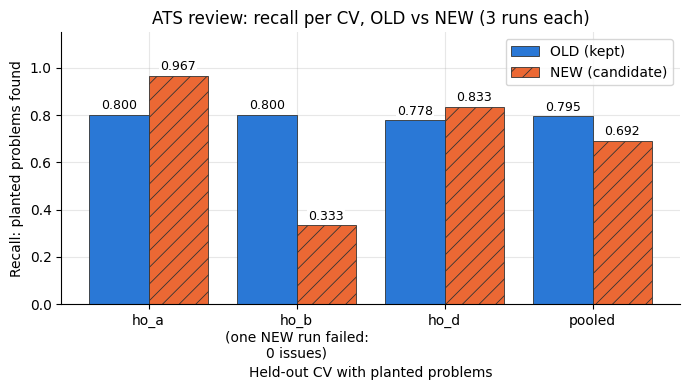

In words: planted problems found, NEW against OLD: ho_a 29/30 against 24/30; ho_b 10/30 against 24/30; ho_d 15/18 against 14/18; pooled 54/78 against 62/78 (change -0.103).


**6. ATS review instructions, not adopted: 29 PASS, 0 FAIL, 0 SKIPPED.**

In [24]:
failed = read_json(ATS / 'runs' / 'heldout' / 'sealed' / 'failed' / 'ho_b_new_r2.json')
attempts = [a.get('kind') for h in failed['history'] for a in h.get('attempts', [])]
m = mapping['ho_b']['labels']['ho_b_06']
print(f"ho_b_06: version {m['version'].upper()}, run {m['run']}, answered: {'yes' if m['answered'] else 'no'}; "
      f"issues counted {stats['ho_b_06']['n']}.")
print(f"Failed record: {failed['failedRuns']} failed runs, {len(attempts)} attempts, kinds: "
      + ', '.join(f'{k} {attempts.count(k)}' for k in sorted(set(attempts))))
totals_line = next(l.strip() for l in read_text(ATS / 'measure' / 'totals.txt').splitlines() if 'SEALED failed file' in l)
print('measure/totals.txt:', totals_line)
check_exact(SEC, 'ho_b_06 (NEW, run 2): answered, issues counted, failed runs', (m['answered'], stats['ho_b_06']['n'], failed['failedRuns']),
            (False, 0, 4), 'grading_mapping.json and sealed/failed/ho_b_new_r2.json', kind='read',
            show=lambda v: f"{'answered' if v[0] else 'not answered'}, {v[1]} issues, {v[2]} failed runs")

# development set: reported, never decides
sec3 = md_text[md_text.index('\n## 3.'):md_text.index('\n## 4.')]
caught = {r['Label']: int(re.match(r'\s*(\d+)', r['Caught']).group(1)) for r in md_table(sec3, '### Planted problems caught (of 12)')}
dev = {v: sum(caught[l] for l in mapping['dev_flawed']['labels'] if version_of[l] == v) for v in ('old', 'new')}
print('\nDevelopment flawed CV, full catches per output (of 12): '
      + ', '.join(f"{l} {n} ({version_of[l].upper()})" for l, n in caught.items()))
print('Partial catches are not counted (as in score_dev.py).')
check_exact(SEC, 'development recall OLD and NEW (reported, never decides)', ((dev['old'], 36), (dev['new'], 36)), E['dev'],
            'README / score_dev.py', show=lambda v: f'OLD {frac(*v[0])}, NEW {frac(*v[1])}')

per_cv = pd.DataFrame({v.upper(): {**{cv: RES[v]['found_cv'][cv] / (3 * len(planted[cv])) for cv in FLAWED},
                                   'pooled': RES[v]['found'] / TOTAL} for v in ('old', 'new')})
per_cv['OLD found'] = [f"{RES['old']['found_cv'][cv]}/{3 * len(planted[cv])}" for cv in FLAWED] + [f"{old['found']}/{TOTAL}"]
per_cv['NEW found'] = [f"{RES['new']['found_cv'][cv]}/{3 * len(planted[cv])}" for cv in FLAWED] + [f"{new['found']}/{TOTAL}"]
per_cv.index.name = 'held-out CV'
display(per_cv.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(per_cv))
b1 = ax.bar(x - 0.2, per_cv['OLD'], 0.4, label='OLD (kept)', **OLD_BAR)
b2 = ax.bar(x + 0.2, per_cv['NEW'], 0.4, label='NEW (candidate)', **NEW_BAR)
bar_labels(ax, b1); bar_labels(ax, b2)
ax.set_xticks(x, [cv + '\n(one NEW run failed:\n0 issues)' if cv == 'ho_b' else cv for cv in per_cv.index])
ax.set_ylim(0, 1.15)
ax.set_xlabel('Held-out CV with planted problems')
ax.set_ylabel('Recall: planted problems found')
ax.set_title('ATS review: recall per CV, OLD vs NEW (3 runs each)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()
print('In words: planted problems found, NEW against OLD: '
      + '; '.join(f"{cv} {per_cv.loc[cv, 'NEW found']} against {per_cv.loc[cv, 'OLD found']}" for cv in FLAWED)
      + f"; pooled {new['found']}/{TOTAL} against {old['found']}/{TOTAL} (change {(new['found'] - old['found']) / TOTAL:+.3f}).")
section_result(SEC)

## 7. Unit tests

**What was tested.** The project's Flutter unit and widget tests (`test/`), which also cover the evaluation tools (for example `test/ranking_metrics_test.dart` checks the ranking metrics against values worked out by hand).

**How.** `flutter test --machine` is run from the repository folder and its event stream is counted per test file: passed, failed and skipped. A skipped test reports "success" too, so skipped tests are counted first. `flutter test` runs on this computer in Flutter's test engine, not on an Android phone or emulator; this notebook measures no speed or behaviour on a phone.

**Expected.** Expected: 575 passed, 0 failed, 1 skipped, in 28 test files. The check passes only with exactly these numbers; tests added later would change them.

In [25]:
SEC = '7. Unit tests'
TESTS = None
if not HAVE_FLUTTER:
    skip(SEC, 'unit tests: passed / failed / skipped', 'flutter is not installed', '575 / 0 / 1', 'flutter test --machine')
else:
    res = run_tool(['flutter', 'test', '--machine'], timeout=1800)
    print(f"$ flutter test --machine   ({res['seconds']:.0f} s, exit code {res['code']})")
    suites, tests, done, errors, success, other_lines = {}, {}, {}, {}, None, 0
    for line in res['raw'].splitlines():
        line = line.strip()
        try:
            ev = json.loads(line) if line.startswith('{') else None
        except ValueError:
            ev = None
        if not isinstance(ev, dict):
            other_lines += 1
            continue
        kind = ev.get('type')
        if kind == 'suite':
            suites[ev['suite']['id']] = scrub(ev['suite'].get('path') or '').lstrip('./').replace('\\', '/')
        elif kind == 'testStart':
            t = ev['test']
            meta = t.get('metadata') or {}
            tests[t['id']] = dict(suite=t.get('suiteID'), name=t.get('name', ''), skip_reason=meta.get('skipReason'))
        elif kind == 'testDone':
            done[ev['testID']] = ev
        elif kind == 'error':
            errors.setdefault(ev.get('testID'), []).append(safe_line(ev.get('error', '')))
        elif kind == 'done':
            success = ev.get('success')
    per_file, skipped, failures = {}, [], []
    for tid, ev in done.items():
        if ev.get('hidden'):
            continue                                  # the "loading <file>" entries
        info = tests.get(tid, {})
        f = suites.get(info.get('suite'), '(unknown file)')
        row = per_file.setdefault(f, dict(passed=0, failed=0, skipped=0))
        if ev.get('skipped'):
            row['skipped'] += 1
            skipped.append({'file': f, 'test': safe_line(info.get('name', '')), 'reason': safe_line(info.get('skip_reason') or '')})
        elif ev.get('result') == 'success':
            row['passed'] += 1
        else:
            row['failed'] += 1
            failures.append({'file': f, 'test': safe_line(info.get('name', '')), 'first error line': (errors.get(tid) or [''])[0]})
    table = pd.DataFrame(per_file).T.sort_index()
    table['total'] = table.sum(axis=1)
    table.loc['all test files'] = table.sum()
    table.index.name = 'test file'
    print(f'{other_lines} lines of build output that are not test events were ignored.')
    display(table)
    for title, rows_ in (('Skipped tests:', skipped), ('Failed tests:', failures)):
        print(title, '' if rows_ else 'none')
        if rows_:
            show_table(pd.DataFrame(rows_))
    tot = table.loc['all test files']
    TESTS = (int(tot['passed']), int(tot['failed']), int(tot['skipped']))
    check_exact(SEC, 'unit tests: passed / failed / skipped', ' / '.join(map(str, TESTS)),
                f"{EXPECTED['tests']['passed']} / {EXPECTED['tests']['failed']} / {EXPECTED['tests']['skipped']}",
                'expected (about 575 tests, 1 skipped)', kind='run')
    check_exact(SEC, 'test files run', len(per_file), EXPECTED['tests']['files'], 'test/', kind='run')
    check_exact(SEC, 'the test run reported success', success, True, 'flutter test --machine', kind='run')
GLANCE['tests'] = {
    'experiment': 'Unit tests (flutter test, on this computer)',
    'compared': '',
    'main number, earlier -> new': ('passed / failed / skipped ' + ' / '.join(map(str, TESTS))) if TESTS else 'not run here',
    'rule outcome': '',
    'decision': '',
}
section_result(SEC)

SKIPPED unit tests: passed / failed / skipped: not run: flutter is not installed | expected 575 / 0 / 1


**7. Unit tests: 0 PASS, 0 FAIL, 1 SKIPPED.**

## 8. Summary: the result at a glance, and every check

First the number of checks per section, then the result of each experiment, then any check that did not pass, then what this notebook does not recompute. The full list of checks comes last. A FAIL would mean that a number found here does not match the saved record or the expected value.

In [26]:
summary = pd.DataFrame(CHECKS)
RESULTS = ['PASS', 'FAIL', 'SKIPPED']
counts = summary['result'].value_counts().reindex(RESULTS, fill_value=0)
order = list(dict.fromkeys(summary['section']))
by_section = (summary.groupby(['section', 'result']).size().unstack(fill_value=0)
              .reindex(index=order, columns=RESULTS, fill_value=0))
by_section.loc['all sections'] = by_section.sum()
print('Checks per section:')
display(by_section)

if counts['FAIL'] == 0:
    text = f"**All {counts['PASS']} checks that ran pass: 0 FAIL.**"
    if counts['SKIPPED']:
        text += f" {counts['SKIPPED']} checks were SKIPPED because a tool is missing here; they are not passes."
else:
    text = (f"**{counts['FAIL']} checks FAIL** ({counts['PASS']} pass, {counts['SKIPPED']} skipped). "
            'They are listed in the table "Checks that did not pass" below.')
display(Markdown(text))

# ---- the result at a glance: one row per experiment
is_expected = summary['source'].str.startswith('expected')
glance_rows = []
for tag, prefixes in (('gaps', ('2. ', '3. ')), ('recommender', ('4. ',)), ('matching', ('5. ',)),
                      ('ats', ('6. ',)), ('tests', ('7. ',))):
    g = GLANCE.get(tag, {'experiment': f'{tag}: section did not finish'})
    rows = summary[is_expected & summary['section'].str.startswith(prefixes)]
    n = rows['result'].value_counts().reindex(RESULTS, fill_value=0)
    glance_rows.append({**g, 'expected numbers checked': f"{n['PASS']} PASS, {n['FAIL']} FAIL, {n['SKIPPED']} SKIPPED"})
print('\nThe result at a glance:')
show_table(pd.DataFrame(glance_rows).fillna(''))

exp = summary[is_expected]
kind_table = pd.DataFrame({'checks of expected numbers': exp['kind'].value_counts(),
                           'all checks': summary['kind'].value_counts()}).reindex([v[0] for v in KINDS.values()])
kind_table = kind_table.fillna(0).astype(int)
kind_table.index.name = 'kind of check'
by_kind = exp['kind'].value_counts()
display(Markdown(f"**Expected numbers: {by_kind.get(KINDS['recomputed'][0], 0)} recomputed from raw data, "
                 f"{by_kind.get(KINDS['read'][0], 0)} read from saved outputs, "
                 f"{by_kind.get(KINDS['run'][0], 0)} found by a tool run now.**"))
display(kind_table)

bad = summary[summary['result'] != 'PASS']
print('\nChecks that did not pass (FAIL or SKIPPED):', 'none' if bad.empty else f'{len(bad)}')
if not bad.empty:
    show_table(bad[['result', 'section', 'check', 'kind', 'found', 'expected', 'source']])

Checks per section:


result,PASS,FAIL,SKIPPED
section,,,
1. The four experiments and their records,4,0,0
2. Skill gaps: final held-out measurement,38,0,0
3. Skill gaps: first held-out round,35,0,0
4. Opportunity recommender,28,0,14
"5. Matching by meaning, not adopted",32,0,0
"6. ATS review instructions, not adopted",29,0,0
7. Unit tests,0,0,1
all sections,166,0,15


**All 166 checks that ran pass: 0 FAIL.** 15 checks were SKIPPED because a tool is missing here; they are not passes.


The result at a glance:


experiment,compared,"main number, earlier -> new",rule outcome,decision,expected numbers checked
Skill gaps (final held-out set),G0E0 (original) vs G1E1 (candidate),FalseGap 0.185 -> 0.005; Recall 0.990 -> 0.956,G1E1 meets 6 of 6 rules,G1E1 adopted,"31 PASS, 0 FAIL, 0 SKIPPED"
Opportunity recommender (8 held-out users),baseline vs new recommender,nDCG@10 0.696 -> 0.806; GapCov@10 0.609 -> 0.750 (saved output),no rule fixed in advance; differences of about 0.02 are noise,new recommender adopted (as recorded),"24 PASS, 0 FAIL, 2 SKIPPED"
Matching by meaning (61 names),A0 (word matching) vs B and B-opp (meaning links),TeachHit@5 0.163 -> 0.457; AttribPrec@5 of B 0.691 (opp) and 0.661 (cert),"rule 7.2 (c), AttribPrec@5 at least 0.70: not met by any candidate",A0 stays,"10 PASS, 0 FAIL, 0 SKIPPED"
ATS review instructions (4 held-out CVs),OLD vs NEW review text,recall 62/78 -> 54/78 (-0.103; rule (a) needs +0.100),rule (a) not met; the other rules met,KEEP OLD,"17 PASS, 0 FAIL, 0 SKIPPED"
"Unit tests (flutter test, on this computer)",,not run here,,,"0 PASS, 0 FAIL, 0 SKIPPED"


**Expected numbers: 57 recomputed from raw data, 27 read from saved outputs, 0 found by a tool run now.**

,checks of expected numbers,all checks
kind of check,,
recomputed from raw data,57,114
read from saved output,27,35
file fingerprint (SHA-256),0,6
count of files or rows,0,13
tool run now,0,13



Checks that did not pass (FAIL or SKIPPED): 15


result,section,check,kind,found,expected,source
SKIPPED,4. Opportunity recommender,held-out: tool run,tool run now,not run: dart is not installed,n/a,evaluate_recommender.dart
SKIPPED,4. Opportunity recommender,held-out: re-run equal to the saved output,tool run now,not run: dart is not installed,n/a,evaluate_recommender.dart
SKIPPED,4. Opportunity recommender,held-out: titles found,tool run now,not run: dart is not installed,n/a,evaluate_recommender.dart
SKIPPED,4. Opportunity recommender,held-out: printed grades,tool run now,not run: dart is not installed,n/a,evaluate_recommender.dart
SKIPPED,4. Opportunity recommender,held-out: labels allow GapCov,tool run now,not run: dart is not installed,n/a,evaluate_recommender.dart
SKIPPED,4. Opportunity recommender,held-out: per-user metrics,tool run now,not run: dart is not installed,n/a,evaluate_recommender.dart
SKIPPED,4. Opportunity recommender,development: tool run,tool run now,not run: dart is not installed,n/a,evaluate_recommender.dart
SKIPPED,4. Opportunity recommender,development: re-run equal to the saved output,tool run now,not run: dart is not installed,n/a,evaluate_recommender.dart
SKIPPED,4. Opportunity recommender,development: titles found,tool run now,not run: dart is not installed,n/a,evaluate_recommender.dart
SKIPPED,4. Opportunity recommender,development: printed grades,tool run now,not run: dart is not installed,n/a,evaluate_recommender.dart


**What this notebook does not recompute, and why**

- *Bundled (detector)* of the skill gaps and of the market names: it uses the app's name-shape detector (`MarketSkillNames.looksBundled`) and the catalogue names, which live in Dart code. The saved values are shown.
- The matching scores other than B's AttribPrec@5, TeachHit@5 and FalseUncovered (A0, L1, L1g and the -opp variants), the matching bootstrap interval of the TeachHit@5 difference, and the persona and timing guards: the scoring tool refuses to run on today's code (README), and only B's attribution lists were saved. These numbers are read from the saved output, and the SHA-256 checks show that file is unchanged.
- *Goal-only above gap* of the recommender: it needs the whole ranked list, and the tool prints only the first 10. The saved values are read and checked against the expected values instead.
- *Ties@10* of the recommender is recomputed, but from the scores printed with 3 decimals, while the tool compares full scores. So the recomputed value can only over-count ties; the per-user checks of Section 4 compare it with the tool's value.
- The baseline TopGapRank of one held-out test user (business analyst, rank 94): only ranks up to 10 can be recomputed; Python confirms that none of the first 10 teaches the top gap and takes the rank from the tool.
- The recommender ablation and the TIMING block: the ablation needs the recommender itself, and times depend on the computer.

The full list of checks follows.

In [27]:
print(f'All {len(summary)} checks, in the order they ran:')
show_table(summary[['result', 'section', 'check', 'kind', 'found', 'expected', 'source']])
print(f'This run took {time.time() - T0:.0f} s.')

All 181 checks, in the order they ran:


result,section,check,kind,found,expected,source
PASS,1. The four experiments and their records,summary line of the project re-check log,read from saved output,"SUMMARY: 9 same, 0 different, 1 skipped.","SUMMARY: 9 same, 0 different, 1 skipped.",evaluation/logs/rerun_2026-11-22.txt
PASS,1. The four experiments and their records,saved answer files in evaluation/skill_gaps/final_run/raw/gaps,count of files or rows,96,96,16 CVs x 2 versions x 3 runs
PASS,1. The four experiments and their records,saved answer files in evaluation/skill_gaps/final_run/raw/market,count of files or rows,54,54,9 career goals x 2 extractors x 3 runs
PASS,1. The four experiments and their records,saved answer files in evaluation/skill_gaps/first_run/raw/gaps,count of files or rows,192,192,16 CVs x 4 versions x 3 runs
PASS,2. Skill gaps: final held-out measurement,names waiting for review (rows of review/names_review.csv),count of files or rows,0,0,evaluation/skill_gaps/final_run/review/names_review.csv
PASS,2. Skill gaps: final held-out measurement,"all CVs, G0E0: all 15 metrics equal scores.json",recomputed from raw data,largest difference 2.2e-16,at most 1e-9,evaluation/skill_gaps/final_run/scores.json
PASS,2. Skill gaps: final held-out measurement,"all CVs, G1E1: all 15 metrics equal scores.json",recomputed from raw data,largest difference 0.0e+00,at most 1e-9,evaluation/skill_gaps/final_run/scores.json
PASS,2. Skill gaps: final held-out measurement,"unseen goals, G0E0: all 15 metrics equal scores.json",recomputed from raw data,largest difference 1.1e-16,at most 1e-9,evaluation/skill_gaps/final_run/scores.json
PASS,2. Skill gaps: final held-out measurement,"unseen goals, G1E1: all 15 metrics equal scores.json",recomputed from raw data,largest difference 0.0e+00,at most 1e-9,evaluation/skill_gaps/final_run/scores.json
PASS,2. Skill gaps: final held-out measurement,"seen goals, G0E0: all 15 metrics equal scores.json",recomputed from raw data,largest difference 2.2e-16,at most 1e-9,evaluation/skill_gaps/final_run/scores.json


This run took 14 s.
